<a href="https://colab.research.google.com/github/nahaaig/Bank-Marketing-KHDL-Nhom16/blob/main/NHOM16_PRJ2_MID_TERM_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mid-term 2 – Dự án 2: Phân tích dữ liệu Bank Marketing
**Nhóm 16** | **Dữ liệu:** `bank.csv` (Kaggle – Bank Marketing Dataset, tác giả janiobachmann) | **Mã nguồn:** https://github.com/nahaaig/Bank-Marketing-KHDL-Nhom16

Notebook trình bày quy trình xử lý dữ liệu từ đầu đến cuối theo 4 giai đoạn:
1. Thu thập và đánh giá dữ liệu ban đầu
2. Tiền xử lý và làm sạch dữ liệu
3. Phân tích và trực quan hóa
4. Đánh giá tác động và khuyến nghị

Thứ tự đọc dữ liệu: (1) file `bank.csv` nằm cạnh notebook / upload vào Colab; (2) nếu không có thì đọc từ GitHub Raw của nhóm; (3) nếu vẫn không được thì Colab sẽ hiện hộp chọn file để upload. Ô 1.2c kiểm tra dữ liệu đúng bản gốc (11.162 dòng) trước khi phân tích, nên mọi con số trong phần nhận xét luôn khớp với kết quả chạy. Có thể chạy toàn bộ notebook bằng **Runtime → Run all**.

# PHẦN 1: THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU

## 1.0. Nguồn dữ liệu, cấu trúc và mục tiêu bài toán
- **Nguồn:** Kaggle – *Bank Marketing Dataset* (tác giả janiobachmann), một file duy nhất `bank.csv`. Dữ liệu ghi lại các cuộc gọi tiếp thị của một ngân hàng nhằm mời khách đăng ký **tiền gửi kỳ hạn**.
- **Cấu trúc:** mỗi dòng là một khách hàng được liên hệ; **11.162 dòng × 17 cột** (7 biến số, 10 biến phân loại).
- **Nhóm thuộc tính:** (1) thông tin khách hàng: `age, job, marital, education`; (2) tài chính: `default, balance, housing, loan`; (3) chiến dịch: `contact, day, month, duration, campaign, pdays, previous, poutcome`; (4) biến mục tiêu: `deposit`.
- **Mục tiêu bài toán:** tìm các yếu tố làm tăng khả năng khách đăng ký tiền gửi kỳ hạn (`deposit = yes`) để đề xuất cách tiếp thị hiệu quả hơn (gọi nhóm khách nào, vào tháng nào, gọi bao nhiêu lần).
- **Tính nhất quán giữa các file:** dữ liệu chỉ có **một bảng**, nên không cần gộp và không phát sinh khóa chính/khóa ngoại.

In [1]:
# 1.1. IMPORT CÁC THƯ VIỆN CẦN THIẾT & CẤU HÌNH HIỂN THỊ
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')  # Ẩn các cảnh báo phiên bản để output gọn gàng

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, RobustScaler, StandardScaler

# Cấu hình hiển thị bảng của Pandas (hiển thị đầy đủ tất cả các cột)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', '{:.2f}'.format)

# Cấu hình giao diện biểu đồ Matplotlib & Seaborn đồng nhất, sắc nét
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

print("Đã import thư viện và cấu hình môi trường thành công!")

Đã import thư viện và cấu hình môi trường thành công!


In [2]:
# 1.2. ĐỌC DỮ LIỆU BANK.CSV VÀ HIỂN THỊ 5 DÒNG ĐẦU TIÊN
# ==============================================================================
# Thứ tự ưu tiên: file bank.csv có sẵn -> GitHub Raw của nhóm -> hộp upload của Colab
import os
os.makedirs('figures', exist_ok=True)   # thư mục chứa hình để chèn vào PDF
os.makedirs('tables', exist_ok=True)    # thư mục chứa bảng số liệu (CSV)
DATA_URL = "https://raw.githubusercontent.com/nahaaig/Bank-Marketing-KHDL-Nhom16/refs/heads/main/bank.csv"

df = None
if os.path.exists('bank.csv'):
    df = pd.read_csv('bank.csv')
    print("Đã đọc file bank.csv có sẵn trong thư mục làm việc")
else:
    try:
        df = pd.read_csv(DATA_URL)
        print("Đã đọc dữ liệu từ GitHub Raw")
    except Exception as err:
        print("Không đọc được GitHub Raw:", type(err).__name__)
        try:
            from google.colab import files          # chỉ có trên Colab
            uploaded = files.upload()               # chọn file bank.csv trong hộp thoại
            df = pd.read_csv(next(iter(uploaded)))
        except ImportError:
            raise FileNotFoundError("Không tìm thấy dữ liệu: hãy đặt bank.csv cạnh notebook hoặc kiểm tra DATA_URL")
assert 'deposit' in df.columns, "Sai file dữ liệu: cần bank.csv của janiobachmann (có cột deposit)"

print(f"Kích thước tập dữ liệu: {df.shape[0]:,} dòng và {df.shape[1]} cột.")
print("\n--- 5 DÒNG ĐẦU TIÊN CỦA TẬP DỮ LIỆU ---")
display(df.head())


Đã đọc dữ liệu từ GitHub Raw
Kích thước tập dữ liệu: 11,162 dòng và 17 cột.

--- 5 DÒNG ĐẦU TIÊN CỦA TẬP DỮ LIỆU ---


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [3]:
# 1.2c. KIỂM TRA TOÀN VẸN DỮ LIỆU: ĐÚNG BẢN bank.csv GỐC (để số liệu trong nhận xét không bị lệch)
# ==============================================================================
# Các con số trong phần nhận xét (Markdown) được viết dựa trên bản bank.csv gốc của Kaggle.
# Ô này dừng notebook ngay nếu ai đó thay nhầm file dữ liệu khác.
expected_cols = ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact',
                 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']
assert list(df.columns) == expected_cols, "Tên/thứ tự cột không khớp bank.csv gốc"
assert df.shape == (11162, 17), f"Kích thước {df.shape} khác bản gốc (11162, 17)"
assert df['deposit'].value_counts().to_dict() == {'no': 5873, 'yes': 5289}, "Phân bố deposit khác bản gốc"
for col, n in {'job': 70, 'education': 497, 'contact': 2346, 'poutcome': 8326}.items():
    assert (df[col] == 'unknown').sum() == n, f"Số 'unknown' của cột {col} khác bản gốc"
assert (df['pdays'] == -1).sum() == 8324, "Số dòng pdays = -1 khác bản gốc"
print("✅ Dữ liệu khớp bản gốc: 11.162 dòng x 17 cột; deposit no/yes = 5.873/5.289. Các nhận xét bên dưới dùng đúng số liệu này.")


✅ Dữ liệu khớp bản gốc: 11.162 dòng x 17 cột; deposit no/yes = 5.873/5.289. Các nhận xét bên dưới dùng đúng số liệu này.


In [4]:
# 1.2b. BẢNG MÔ TẢ THUỘC TÍNH (Ý NGHĨA, KIỂU DỮ LIỆU, SỐ GIÁ TRỊ KHÁC NHAU)
meaning = {
    "age": "Tuổi khách hàng", "job": "Nghề nghiệp", "marital": "Tình trạng hôn nhân", "education": "Trình độ học vấn",
    "default": "Có nợ xấu (vỡ nợ tín dụng) hay không", "balance": "Số dư tài khoản trung bình năm (euro, có thể âm)",
    "housing": "Có vay mua nhà hay không", "loan": "Có vay cá nhân hay không",
    "contact": "Hình thức liên hệ (cellular, telephone, unknown)", "day": "Ngày trong tháng của lần liên hệ cuối",
    "month": "Tháng của lần liên hệ cuối", "duration": "Thời lượng cuộc gọi cuối (giây), chỉ biết SAU cuộc gọi",
    "campaign": "Số lần liên hệ khách trong chiến dịch này", "pdays": "Số ngày từ lần liên hệ chiến dịch trước (-1 = chưa từng liên hệ)",
    "previous": "Số lần liên hệ trước chiến dịch này", "poutcome": "Kết quả chiến dịch trước (success, failure, other, unknown)",
    "deposit": "BIẾN MỤC TIÊU: có đăng ký tiền gửi kỳ hạn không (yes/no)",
}
attr_table = pd.DataFrame({
    "Thuộc tính": df.columns,
    "Ý nghĩa": [meaning[c] for c in df.columns],
    "Kiểu dữ liệu": [str(df[c].dtype) for c in df.columns],
    "Số giá trị khác nhau": [df[c].nunique() for c in df.columns],
})
display(attr_table)

,Thuộc tính,Ý nghĩa,Kiểu dữ liệu,Số giá trị khác nhau
0,age,Tuổi khách hàng,int64,76
1,job,Nghề nghiệp,object,12
2,marital,Tình trạng hôn nhân,object,3
3,education,Trình độ học vấn,object,4
4,default,Có nợ xấu (vỡ nợ tín dụng) hay không,object,2
5,balance,"Số dư tài khoản trung bình năm (euro, có thể âm)",int64,3805
6,housing,Có vay mua nhà hay không,object,2
7,loan,Có vay cá nhân hay không,object,2
8,contact,"Hình thức liên hệ (cellular, telephone, unknown)",object,3
9,day,Ngày trong tháng của lần liên hệ cuối,int64,31


In [5]:
# 1.3. KIỂM TRA KIỂU DỮ LIỆU (INFO) & THỐNG KÊ MÔ TẢ (DESCRIBE)
# ==============================================================================
print("--- 1. THÔNG TIN CẤU TRÚC VÀ KIỂU DỮ LIỆU TỪNG TRƯỜNG ---")
df.info()

# Thống kê mô tả cho 7 biến số (Numerical features)
# Lý do kỹ thuật: Giúp nhận diện nhanh độ lệch phân phối (Mean vs Median) và các cực trị (Min/Max)
print("\n--- 2. THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ (NUMERICAL FEATURES) ---")
display(df.describe().T)

# Thống kê mô tả cho 10 biến phân loại (Categorical features)
# Lý do kỹ thuật: Giúp kiểm tra số lượng nhãn duy nhất (unique) và giá trị phổ biến nhất (top/Mode)
print("\n--- 3. THỐNG KÊ MÔ TẢ CÁC BIẾN PHÂN LOẠI (CATEGORICAL FEATURES) ---")
display(df.describe(include=['object', 'string']).T)

--- 1. THÔNG TIN CẤU TRÚC VÀ KIỂU DỮ LIỆU TỪNG TRƯỜNG ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB

--- 2. THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ (NUMER

,count,mean,std,min,25%,50%,75%,max
age,11162.00,41.23,11.91,18.00,32.00,39.00,49.00,95.00
balance,11162.00,1528.54,3225.41,-6847.00,122.00,550.00,1708.00,81204.00
day,11162.00,15.66,8.42,1.00,8.00,15.00,22.00,31.00
duration,11162.00,371.99,347.13,2.00,138.00,255.00,496.00,3881.00
campaign,11162.00,2.51,2.72,1.00,1.00,2.00,3.00,63.00
pdays,11162.00,51.33,108.76,-1.00,-1.00,-1.00,20.75,854.00
previous,11162.00,0.83,2.29,0.00,0.00,0.00,1.00,58.00



--- 3. THỐNG KÊ MÔ TẢ CÁC BIẾN PHÂN LOẠI (CATEGORICAL FEATURES) ---


,count,unique,top,freq
job,11162,12,management,2566
marital,11162,3,married,6351
education,11162,4,secondary,5476
default,11162,2,no,10994
housing,11162,2,no,5881
loan,11162,2,no,9702
contact,11162,3,cellular,8042
month,11162,12,may,2824
poutcome,11162,4,unknown,8326
deposit,11162,2,no,5873


In [6]:
# 1.4. KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU (NULL/NAN) VÀ GIÁ TRỊ ẨN 'UNKNOWN'
# ==============================================================================
# Trong tập dữ liệu Bank Marketing, dữ liệu bị thiếu thường không lưu dưới dạng NaN
# mà được mã hóa ẩn dưới chuỗi ký tự 'unknown'. Do đó cần kiểm tra cả hai.

missing_summary = []
for col in df.columns:
    null_count = df[col].isnull().sum()
    null_pct = (null_count / len(df)) * 100

    # Đếm số lượng chuỗi 'unknown' nếu cột có kiểu chuỗi (object)
    if df[col].dtype == 'object' or str(df[col].dtype) in ('str', 'string'):
        unk_count = (df[col] == 'unknown').sum()
    else:
        unk_count = 0
    unk_pct = (unk_count / len(df)) * 100

    missing_summary.append({
        'Tên cột': col,
        'Kiểu dữ liệu': str(df[col].dtype),
        'Số lượng Null (NaN)': null_count,
        'Tỷ lệ Null (%)': round(null_pct, 2),
        "Số lượng 'unknown'": unk_count,
        "Tỷ lệ 'unknown' (%)": round(unk_pct, 2)
    })

df_missing_report = pd.DataFrame(missing_summary)
print("--- BẢNG THỐNG KÊ GIÁ TRỊ KHUYẾT THIẾU (NULL) VÀ GIÁ TRỊ ẨN ('UNKNOWN') ---")
display(df_missing_report)

print("\n--- CÁC CỘT CÓ CHỨA GIÁ TRỊ 'UNKNOWN' CẦN XỬ LÝ Ở GIAI ĐOẠN 2 ---")
display(df_missing_report[df_missing_report["Số lượng 'unknown'"] > 0])

--- BẢNG THỐNG KÊ GIÁ TRỊ KHUYẾT THIẾU (NULL) VÀ GIÁ TRỊ ẨN ('UNKNOWN') ---


,Tên cột,Kiểu dữ liệu,Số lượng Null (NaN),Tỷ lệ Null (%),Số lượng 'unknown',Tỷ lệ 'unknown' (%)
0,age,int64,0,0.00,0,0.00
1,job,object,0,0.00,70,0.63
2,marital,object,0,0.00,0,0.00
3,education,object,0,0.00,497,4.45
4,default,object,0,0.00,0,0.00
5,balance,int64,0,0.00,0,0.00
6,housing,object,0,0.00,0,0.00
7,loan,object,0,0.00,0,0.00
8,contact,object,0,0.00,2346,21.02
9,day,int64,0,0.00,0,0.00



--- CÁC CỘT CÓ CHỨA GIÁ TRỊ 'UNKNOWN' CẦN XỬ LÝ Ở GIAI ĐOẠN 2 ---


,Tên cột,Kiểu dữ liệu,Số lượng Null (NaN),Tỷ lệ Null (%),Số lượng 'unknown',Tỷ lệ 'unknown' (%)
1,job,object,0,0.00,70,0.63
3,education,object,0,0.00,497,4.45
8,contact,object,0,0.00,2346,21.02
15,poutcome,object,0,0.00,8326,74.59


In [7]:
# 1.5. KIỂM TRA DỮ LIỆU TRÙNG LẶP (DUPLICATES)
# ==============================================================================
dup_count = df.duplicated().sum()
print(f"Số lượng bản ghi bị trùng lặp hoàn toàn: {dup_count} dòng (Tỷ lệ: {dup_count/len(df)*100:.2f}%).")

Số lượng bản ghi bị trùng lặp hoàn toàn: 0 dòng (Tỷ lệ: 0.00%).


### Nhận xét Giai đoạn 1
- **Kích thước:** 11.162 dòng × 17 cột; không có giá trị NaN ở bất kỳ cột nào và không có dòng trùng lặp (0 dòng).
- **Thiếu trá hình:** `isnull()` báo 0 nhưng dữ liệu vẫn thiếu dưới dạng `unknown`: `poutcome` 8.326 dòng (74,59%), `contact` 2.346 dòng (21,02%), `education` 497 dòng (4,45%), `job` 70 dòng (0,63%).
- **Biến mục tiêu:** `no` 5.873 khách (52,62%), `yes` 5.289 khách (47,38%). Dữ liệu **khá cân bằng**, nên tỷ lệ gửi tiền chung 47,38% được dùng làm mốc so sánh.
- **Độ lệch và thiếu dữ liệu cần lưu ý:** `balance` lệch phải rõ rệt (trung bình ≈ 1.529 so với trung vị 550, giá trị lớn nhất 81.204); `poutcome` thiếu tới 74,59% nhưng thực chất là nhóm chưa từng được liên hệ ở chiến dịch trước (xem mục 2.0), nên được giữ làm một nhãn riêng thay vì điền khuyết.

# PHẦN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU

## 2.0. Kiểm tra sai định dạng / giá trị bất hợp lệ
Phần này minh chứng ba nhóm bất thường: **sai định dạng, trùng lặp, ngoại lệ**. Trùng lặp đã kiểm tra ở mục 1.5, ngoại lệ được xử lý ở mục 2.2; ô dưới kiểm tra phần **sai định dạng**.

In [8]:
# 2.0. KIỂM TRA SAI ĐỊNH DẠNG: THÁNG HỢP LỆ, KHOẢNG GIÁ TRỊ, GIÁ TRỊ ÂM, MÃ pdays = -1
months_valid = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
print("Tháng ngoài danh sách hợp lệ:", sorted(set(df['month']) - set(months_valid)) or "không có")
print("Tuổi: min =", df['age'].min(), "| max =", df['age'].max())
print("Ngày: min =", df['day'].min(), "| max =", df['day'].max(), "(phải nằm trong 1-31)")

neg_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
print("\nSố giá trị âm theo cột:")
print((df[neg_cols] < 0).sum().to_string())
print("\n-> balance âm = tài khoản đang thấu chi (dữ liệu thật); pdays = -1 là MÃ 'chưa từng liên hệ', không phải lỗi.")

# Bằng chứng: pdays = -1 trùng gần như hoàn toàn với poutcome = 'unknown'
print("\nĐối chiếu pdays = -1 với poutcome = 'unknown':")
print(pd.crosstab(df['pdays'] == -1, df['poutcome'] == 'unknown', rownames=['pdays = -1'], colnames=["poutcome = 'unknown'"]).to_string())

Tháng ngoài danh sách hợp lệ: không có
Tuổi: min = 18 | max = 95
Ngày: min = 1 | max = 31 (phải nằm trong 1-31)

Số giá trị âm theo cột:
age            0
balance      688
day            0
duration       0
campaign       0
pdays       8324
previous       0

-> balance âm = tài khoản đang thấu chi (dữ liệu thật); pdays = -1 là MÃ 'chưa từng liên hệ', không phải lỗi.

Đối chiếu pdays = -1 với poutcome = 'unknown':
poutcome = 'unknown'  False  True 
pdays = -1                        
False                  2836      2
True                      0   8324


**Nhận xét 2.0:** tháng đều hợp lệ (12 giá trị); tuổi từ 18 đến 95 và ngày từ 1 đến 31 đều nằm trong khoảng hợp lý, không phát hiện lỗi định dạng. `balance` âm là tài khoản thấu chi (dữ liệu thật) nên được giữ nguyên. `pdays = -1` là **mã quy ước** "chưa từng liên hệ" và gần như trùng với `poutcome = unknown` (bảng đối chiếu phía trên), vì vậy được tách thành cột nhị phân `contacted_before` và không đưa vào bước scale ở mục 2.3.

In [9]:
# 2.1. XỬ LÝ GIÁ TRỊ ẨN 'UNKNOWN'
# ==============================================================================
# Tạo bản sao df_clean từ df gốc để đảm bảo tính toàn vẹn dữ liệu
df_clean = df.copy()

# LÝ DO KỸ THUẬT LỰA CHỌN PHƯƠNG PHÁP:
# 1. Cột 'job' (70 dòng ~ 0.63%) và 'education' (497 dòng ~ 4.45%) có tỷ lệ 'unknown' < 5% (rất nhỏ).
#    -> Điền khuyết bằng giá trị xuất hiện nhiều nhất (Mode) của cột đó để làm sạch nhiễu mà không làm méo phân phối.
# 2. Cột 'contact' (2,346 dòng ~ 21.02%) và 'poutcome' (8,326 dòng ~ 74.59%, tương ứng khách hàng chưa từng
#    được liên hệ ở chiến dịch trước khi pdays = -1) có tỷ lệ 'unknown' quá lớn (> 20%).
#    -> Tuyệt đối KHÔNG thay bằng Mode vì sẽ gây sai lệch nghiêm trọng (data distortion).
#    -> Giữ nguyên 'unknown' như một nhãn phân loại độc lập (Separate Category) mang ý nghĩa thông tin riêng.

print("--- TRƯỚC KHI XỬ LÝ 'UNKNOWN' (4 CỘT BỊ ẢNH HƯỞNG) ---")
for col in ['job', 'education', 'contact', 'poutcome']:
    cnt = (df_clean[col] == 'unknown').sum()
    print(f"- Cột {col:10s}: {cnt:5d} giá trị 'unknown' ({cnt/len(df_clean)*100:.2f}%)")

# Thực hiện thay thế 'unknown' bằng Mode cho 'job' và 'education'
for col in ['job', 'education']:
    # Tìm Mode trên tập các giá trị hợp lệ (khác 'unknown')
    mode_val = df_clean[df_clean[col] != 'unknown'][col].mode()[0]
    df_clean[col] = df_clean[col].replace('unknown', mode_val)
    print(f"\n-> Đã thay thế 'unknown' ở cột '{col}' bằng giá trị Mode: '{mode_val}'")

print("\n--- SAU KHI XỬ LÝ 'UNKNOWN' ---")
for col in ['job', 'education', 'contact', 'poutcome']:
    cnt = (df_clean[col] == 'unknown').sum()
    print(f"- Cột {col:10s}: {cnt:5d} giá trị 'unknown' ({cnt/len(df_clean)*100:.2f}%)")

--- TRƯỚC KHI XỬ LÝ 'UNKNOWN' (4 CỘT BỊ ẢNH HƯỞNG) ---
- Cột job       :    70 giá trị 'unknown' (0.63%)
- Cột education :   497 giá trị 'unknown' (4.45%)
- Cột contact   :  2346 giá trị 'unknown' (21.02%)
- Cột poutcome  :  8326 giá trị 'unknown' (74.59%)

-> Đã thay thế 'unknown' ở cột 'job' bằng giá trị Mode: 'management'

-> Đã thay thế 'unknown' ở cột 'education' bằng giá trị Mode: 'secondary'

--- SAU KHI XỬ LÝ 'UNKNOWN' ---
- Cột job       :     0 giá trị 'unknown' (0.00%)
- Cột education :     0 giá trị 'unknown' (0.00%)
- Cột contact   :  2346 giá trị 'unknown' (21.02%)
- Cột poutcome  :  8326 giá trị 'unknown' (74.59%)


--- 1. BẢNG THỐNG KÊ OUTLIERS TRƯỚC KHI XỬ LÝ ---


,Tên cột,Q1 (25%),Median (50%),Q3 (75%),IQR,Ngưỡng dưới (Lower),Ngưỡng trên (Upper),Số lượng Outliers,Tỷ lệ Outliers (%)
0,age,32.00,39.00,49.00,17.00,6.50,74.50,171,1.53
1,balance,122.00,550.00,1708.00,1586.00,-2257.00,4087.00,1055,9.45
2,duration,138.00,255.00,496.00,358.00,-399.00,1033.00,636,5.70
3,campaign,1.00,2.00,3.00,2.00,-2.00,6.00,601,5.38
4,previous,0.00,0.00,1.00,1.00,-1.50,2.50,1258,11.27


Số dòng có ít nhất 1 outlier ở 5 cột: 3,322 dòng (29.8% dữ liệu) -> nếu xóa sẽ mất chừng đó khách thật.

--- 2. BẢNG THỐNG KÊ OUTLIERS SAU KHI CAPPING (WINSORIZATION) ---


,Tên cột,Q1 (25%),Median (50%),Q3 (75%),IQR,Ngưỡng dưới (Lower),Ngưỡng trên (Upper),Số lượng Outliers,Tỷ lệ Outliers (%)
0,age,32.00,39.00,49.00,17.00,6.50,74.50,0,0.00
1,balance,122.00,550.00,1708.00,1586.00,-2257.00,4087.00,0,0.00
2,duration,138.00,255.00,496.00,358.00,-399.00,1033.00,0,0.00
3,campaign,1.00,2.00,3.00,2.00,-2.00,6.00,0,0.00
4,previous,0.00,0.00,1.00,1.00,-1.50,2.50,0,0.00


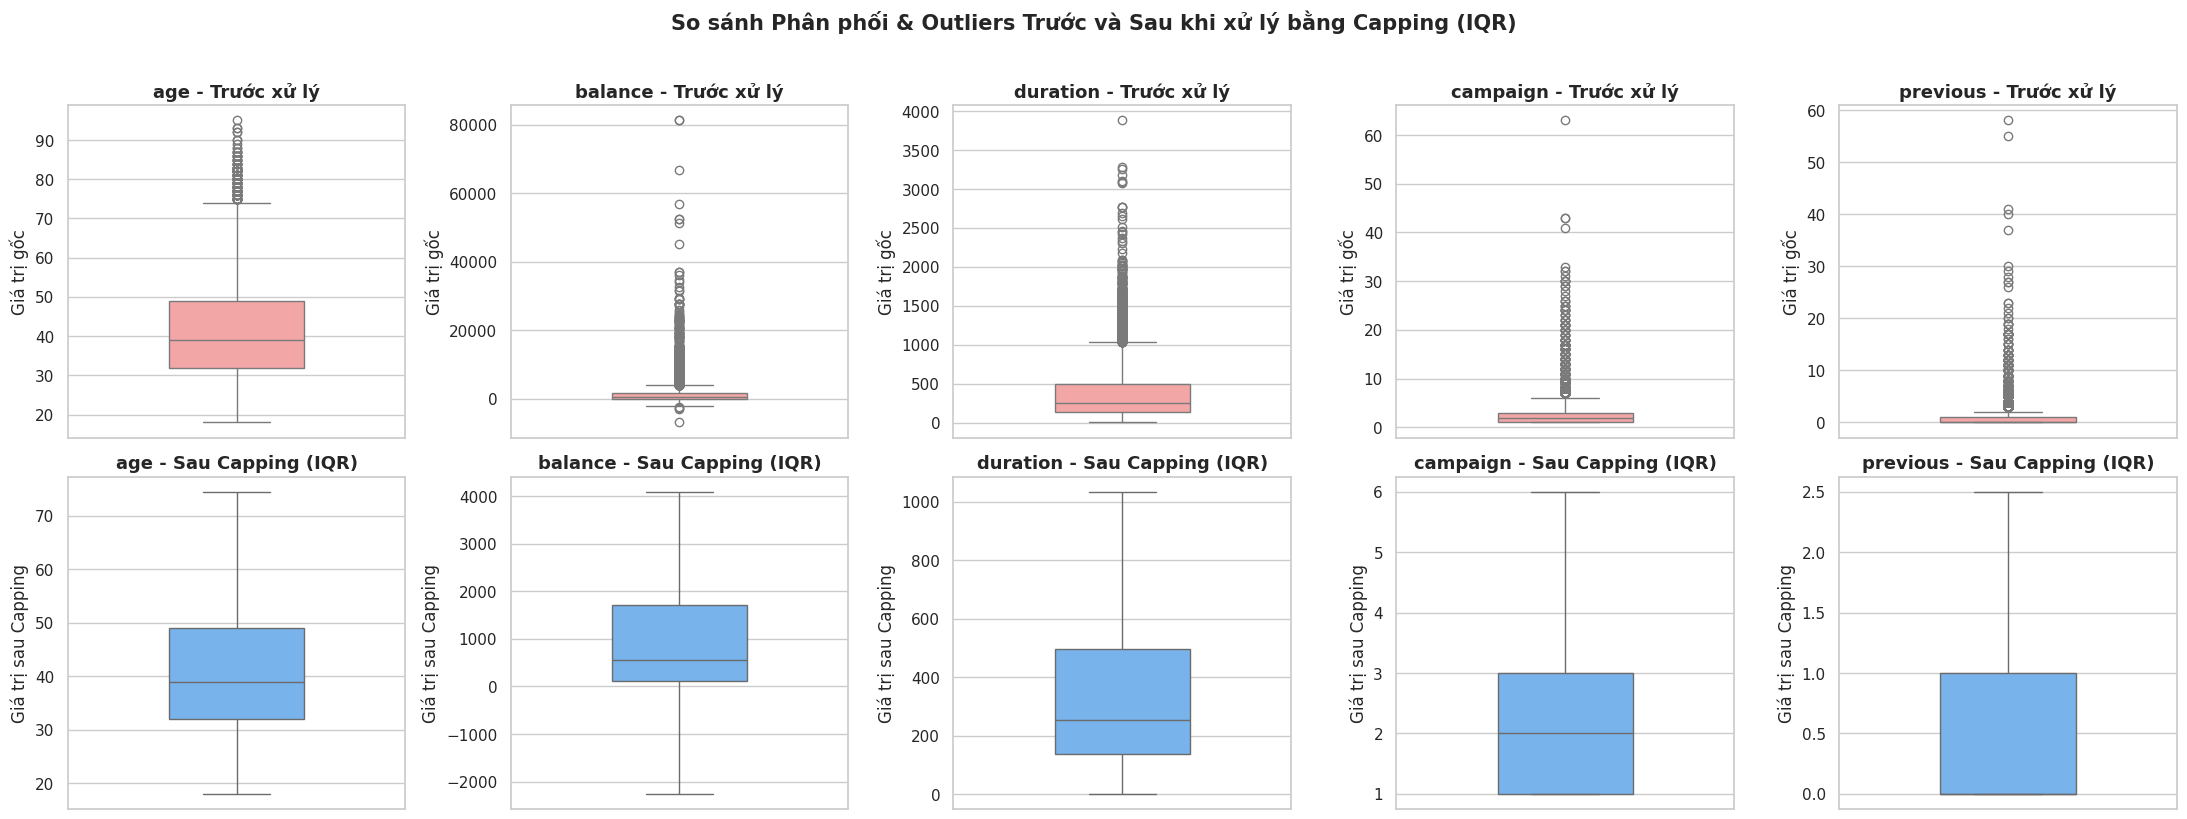

In [10]:
# 2.2. PHÁT HIỆN VÀ XỬ LÝ OUTLIERS BẰNG PHƯƠNG PHÁP IQR (WINSORIZATION / CAPPING)
# ==============================================================================
# Gồm cả 'previous' (lệch phải mạnh) để đồng nhất với bước scale phía sau
num_cols_outlier = ['age', 'balance', 'duration', 'campaign', 'previous']

def detect_outliers_iqr(data, cols):
    """Hàm thống kê số lượng và tỷ lệ Outliers theo phương pháp IQR."""
    report = []
    for col in cols:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]
        report.append({
            'Tên cột': col,
            'Q1 (25%)': Q1,
            'Median (50%)': data[col].median(),
            'Q3 (75%)': Q3,
            'IQR': IQR,
            'Ngưỡng dưới (Lower)': lower_bound,
            'Ngưỡng trên (Upper)': upper_bound,
            'Số lượng Outliers': len(outliers),
            'Tỷ lệ Outliers (%)': round(len(outliers) / len(data) * 100, 2)
        })
    return pd.DataFrame(report)

print("--- 1. BẢNG THỐNG KÊ OUTLIERS TRƯỚC KHI XỬ LÝ ---")
display(detect_outliers_iqr(df_clean, num_cols_outlier))

# Bằng chứng cho lý do 'cắt (capping) chứ không xóa': nếu xóa mọi dòng có ít nhất 1 outlier sẽ mất bao nhiêu dòng?
mask_any_outlier = pd.Series(False, index=df_clean.index)
for _col in num_cols_outlier:
    _q1, _q3 = df_clean[_col].quantile(0.25), df_clean[_col].quantile(0.75)
    _iqr = _q3 - _q1
    mask_any_outlier |= (df_clean[_col] < _q1 - 1.5 * _iqr) | (df_clean[_col] > _q3 + 1.5 * _iqr)
print(f"Số dòng có ít nhất 1 outlier ở {len(num_cols_outlier)} cột: {mask_any_outlier.sum():,} dòng "
      f"({mask_any_outlier.mean() * 100:.1f}% dữ liệu) -> nếu xóa sẽ mất chừng đó khách thật.")

# LÝ DO KỸ THUẬT CHỌN CAPPING (WINSORIZATION) THAY VÌ XÓA BỎ (DROPPING):
# - Riêng cột 'balance' có tới 1,055 dòng ngoại lệ (9.45%), 'duration' có 636 dòng (5.70%), 'campaign' có 601 dòng (5.38%).
# - Trong bài toán ngân hàng, khách hàng có số dư (balance) rất cao hoặc thời lượng tư vấn (duration) dài là dữ liệu thực tế
#   mang giá trị thông tin quan trọng, không phải lỗi nhập liệu. Nếu xóa bỏ (drop) mọi dòng có outlier sẽ mất gần 30% dữ liệu (xem số dòng in ngay bên dưới bảng).
# - Do đó, ta tạo bản sao `df_capped` áp dụng kỹ thuật Capping (ép các giá trị vượt ngưỡng về đúng biên Lower/Upper của IQR)
#   để phục vụ tiền xử lý mô hình mà vẫn giữ nguyên 100% số lượng quan sát (11,162 dòng).

df_capped = df_clean.copy()
for col in num_cols_outlier:
    Q1 = df_capped[col].quantile(0.25)
    Q3 = df_capped[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_capped[col] = df_capped[col].clip(lower=lower_bound, upper=upper_bound)

print("\n--- 2. BẢNG THỐNG KÊ OUTLIERS SAU KHI CAPPING (WINSORIZATION) ---")
display(detect_outliers_iqr(df_capped, num_cols_outlier))

# Vẽ biểu đồ Boxplot minh chứng Trước và Sau khi xử lý Outliers
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
fig.suptitle('So sánh Phân phối & Outliers Trước và Sau khi xử lý bằng Capping (IQR)', fontsize=15, fontweight='bold', y=1.02)

for i, col in enumerate(num_cols_outlier):
    # Hàng 1: Trước khi xử lý (df_clean)
    sns.boxplot(y=df_clean[col], ax=axes[0, i], color='#ff9999', width=0.4)
    axes[0, i].set_title(f'{col} - Trước xử lý', fontweight='bold')
    axes[0, i].set_ylabel('Giá trị gốc')

    # Hàng 2: Sau khi xử lý Capping (df_capped)
    sns.boxplot(y=df_capped[col], ax=axes[1, i], color='#66b3ff', width=0.4)
    axes[1, i].set_title(f'{col} - Sau Capping (IQR)', fontweight='bold')
    axes[1, i].set_ylabel('Giá trị sau Capping')

plt.tight_layout()
plt.savefig('figures/bd_outlier_truoc_sau_capping.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# 2.3. MÃ HÓA DỮ LIỆU PHÂN LOẠI (ENCODING) & CHUẨN HÓA BIẾN SỐ (SCALING)
# ==============================================================================
# Tạo bản sao df_processed từ df_capped để thực hiện Encoding & Scaling
# (Giữ nguyên df_clean và df_capped để phục vụ vẽ biểu đồ EDA ở Phần 3 không bị mất nhãn gốc)
df_processed = df_capped.copy()

# pdays = -1 là MÃ 'chưa từng liên hệ' nên tạo cột nhị phân contacted_before và bỏ pdays khỏi bước scale
df_processed['contacted_before'] = (df_clean['pdays'] != -1).astype(int)
df_processed = df_processed.drop(columns=['pdays'])

# ------------------------------------------------------------------------------
# BƯỚC A: MÃ HÓA BIẾN PHÂN LOẠI (ENCODING)
# ------------------------------------------------------------------------------
# 1. Binary Encoding (Mã hóa nhị phân 0/1) cho các biến chỉ có 2 giá trị 'yes'/'no'
binary_cols = ['default', 'housing', 'loan', 'deposit']
for col in binary_cols:
    df_processed[col] = df_processed[col].map({'no': 0, 'yes': 1})

# 2. Ordinal Encoding (Mã hóa có thứ tự) cho các biến có cấp bậc tự nhiên
# - Cột 'education': primary (1) < secondary (2) < tertiary (3)
edu_mapping = {'primary': 1, 'secondary': 2, 'tertiary': 3}
df_processed['education'] = df_processed['education'].map(edu_mapping)

# - Cột 'month': Mã hóa theo đúng thứ tự thời gian từ tháng 1 đến tháng 12
month_mapping = {
    'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
    'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12
}
df_processed['month'] = df_processed['month'].map(month_mapping)

# 3. One-Hot Encoding cho các biến danh định (Nominal - không có thứ tự cao thấp)
# Sử dụng drop_first=True để tránh hiện tượng đa cộng tuyến hoàn hảo (Dummy Variable Trap)
nominal_cols = ['job', 'marital', 'contact', 'poutcome']
df_processed = pd.get_dummies(df_processed, columns=nominal_cols, drop_first=True, dtype=int)

# ------------------------------------------------------------------------------
# BƯỚC B: CHUẨN HÓA BIẾN SỐ (SCALING)
# ------------------------------------------------------------------------------
# LÝ DO KỸ THUẬT CHỌN ROBUSTSCALER:
# Các biến số như 'balance', 'duration', 'campaign', 'previous' có phân phối lệch phải (right-skewed)
# rất mạnh. RobustScaler chuẩn hóa dựa trên Trung vị (Median) và Khoảng tứ phân vị (IQR) theo công thức:
# X_scaled = (X - Median) / IQR, giúp dữ liệu sau chuẩn hóa ổn định và kháng nhiễu tốt hơn StandardScaler.
print("Skewness (độ lệch) của các biến số gốc, căn cứ để chọn RobustScaler:")
print(df_clean[['balance', 'duration', 'campaign', 'previous', 'pdays']].skew().round(2).to_string())
num_cols_to_scale = ['age', 'balance', 'day', 'duration', 'campaign', 'previous']
scaler = RobustScaler()
df_processed[num_cols_to_scale] = scaler.fit_transform(df_processed[num_cols_to_scale])

print(f"Kích thước bảng df_processed sau khi Encoding & Scaling: {df_processed.shape[0]:,} dòng x {df_processed.shape[1]} cột.")
print("\n--- 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU SAU KHI MÃ HÓA VÀ CHUẨN HÓA (DF_PROCESSED) ---")
display(df_processed.head())

print("\n--- THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ SAU KHI CHUẨN HÓA BẰNG ROBUSTSCALER ---")
display(df_processed[num_cols_to_scale].describe().T)

Skewness (độ lệch) của các biến số gốc, căn cứ để chọn RobustScaler:
balance    8.22
duration   2.14
campaign   5.55
previous   7.34
pdays      2.45
Kích thước bảng df_processed sau khi Encoding & Scaling: 11,162 dòng x 30 cột.

--- 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU SAU KHI MÃ HÓA VÀ CHUẨN HÓA (DF_PROCESSED) ---


,age,education,default,balance,housing,loan,day,month,duration,campaign,previous,deposit,contacted_before,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_married,marital_single,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown
0,1.18,2,0,1.13,1,0,-0.71,5,2.17,-0.50,0.00,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1
1,1.00,2,0,-0.32,0,0,-0.71,5,2.17,-0.50,0.00,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1
2,0.12,2,0,0.45,1,0,-0.71,5,2.17,-0.50,0.00,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,1
3,0.94,2,0,1.21,1,0,-0.71,5,0.91,-0.50,0.00,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,1
4,0.88,3,0,-0.23,0,0,-0.71,5,1.17,0.00,0.00,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1



--- THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ SAU KHI CHUẨN HÓA BẰNG ROBUSTSCALER ---


,count,mean,std,min,25%,50%,75%,max
age,11162.00,0.13,0.69,-1.24,-0.41,0.00,0.59,2.09
balance,11162.00,0.36,0.85,-1.77,-0.27,0.00,0.73,2.23
day,11162.00,0.05,0.60,-1.00,-0.50,0.00,0.50,1.14
duration,11162.00,0.27,0.80,-0.71,-0.33,0.00,0.67,2.17
campaign,11162.00,0.12,0.76,-0.50,-0.50,0.00,0.50,2.00
previous,11162.00,0.49,0.89,0.00,0.00,0.00,1.00,2.50


In [12]:
# 2.3b. KIỂM TRA SAU KHI CHUẨN HÓA: RobustScaler đưa Median về ≈ 0 và IQR về ≈ 1
q = df_processed[num_cols_to_scale]
display(pd.DataFrame({'Median sau scale': q.median(), 'IQR sau scale': q.quantile(0.75) - q.quantile(0.25)}))

,Median sau scale,IQR sau scale
age,0.00,1.00
balance,0.00,1.00
day,0.00,1.00
duration,0.00,1.00
campaign,0.00,1.00
previous,0.00,1.00


### Giải trình kỹ thuật tổng hợp Giai đoạn 2

| Vấn đề (số liệu thật) | Giải pháp | Lý do |
|---|---|---|
| `unknown` thấp ở `job` (0,63%) và `education` (4,45%) | Điền **Mode** (`management`, `secondary`) | Tỷ lệ nhỏ nên không cần bỏ dòng, ít làm méo phân phối; cột chữ không tính được trung bình |
| `unknown` cao ở `contact` (21,02%) và `poutcome` (74,59%) | **Giữ làm một nhóm riêng** | Điền bừa tạo thông tin giả; `poutcome = unknown` thực chất là chưa từng liên hệ (trùng với `pdays = -1`) |
| Outlier ở `balance` (9,45%), `duration` (5,70%), `campaign` (5,38%), `previous` | **Capping IQR**, không xóa | Là khách thật; xóa sẽ mất gần 30% dữ liệu (3.322 dòng, 29,8%, có ít nhất một outlier ở 5 cột); cắt ngưỡng giảm kéo lệch |
| `pdays = -1` (8.324 dòng) | Tạo `contacted_before`, bỏ `pdays` khỏi scale | -1 là mã, không phải số ngày thật; scale như số sẽ làm sai thang đo |
| Biến phân loại | Binary (`default, housing, loan, deposit`), Ordinal (`education`, `month`), One-Hot (`job, marital, contact, poutcome`) | One-Hot cho cột không có thứ tự (đánh số sẽ khiến mô hình hiểu nhầm "student > admin"); Ordinal khi có thứ tự tự nhiên; `drop_first=True` tránh đa cộng tuyến |
| Biến số lệch phải (skewness `balance` ≈ 8,22; `previous` ≈ 7,34; `campaign` ≈ 5,55) | **RobustScaler** | Dựa trên median và IQR nên ít bị outlier kéo lệch; không dùng MinMax vì nhạy với giá trị cực đại |

**Về `age` và so sánh trước/sau capping:** `age` cũng được cắt theo IQR để đồng nhất quy trình (171 dòng, 1,53%, ngưỡng trên 74,5 tuổi); các biểu đồ phân tích ở Phần 3 vẫn dùng dữ liệu gốc nên không mất khách lớn tuổi. Biểu đồ boxplot trước/sau capping cho thấy các điểm ngoại lệ biến mất sau khi cắt, trong khi Q1, trung vị và Q3 giữ nguyên (bảng thống kê sau capping có 0 outlier ở mọi cột). Như vậy capping chỉ cắt phần đuôi chứ không làm thay đổi phần thân của phân phối.

# PHẦN 3: TRỰC QUAN HÓA DỮ LIỆU & THỐNG KÊ SỐ LIỆU

## 3.0. Giả thuyết cần kiểm định và cách đọc kết quả

| Mã | Giả thuyết (đối chiếu số liệu với giả định ban đầu) | Biểu đồ dùng |
|---|---|---|
| H1 | Khách lớn tuổi có tỷ lệ gửi tiền cao hơn khách trẻ | Biểu đồ 3 (bảng 3B) |
| H2 | Nhóm student, retired cao hơn nhóm blue-collar, services | Biểu đồ 2 |
| H3 | Học vấn cao hơn thì tỷ lệ cao hơn; khách độc thân cao hơn khách đã kết hôn | Biểu đồ 2 và 8 |
| H4 | Số dư cao hơn thì tỷ lệ gửi tiền cao hơn | Biểu đồ 3 và 3C |
| H5 | Khách có vay nhà, vay cá nhân hoặc nợ xấu có tỷ lệ thấp hơn | Biểu đồ 7 |
| H6 | Tỷ lệ khác nhau rõ giữa các tháng; tháng ít cuộc gọi thì kém tin cậy | Biểu đồ 5 |
| H7 | Gọi qua cellular hiệu quả hơn telephone và unknown | Biểu đồ 9 |
| H8 | Cuộc gọi dài hơn thì tỷ lệ cao hơn (là **kết quả**, không phải nguyên nhân) | Biểu đồ 4 |
| H9 | Gọi càng nhiều lần thì tỷ lệ càng giảm (tìm ngưỡng dừng) | Biểu đồ 4 và 4D |
| H10 | Khách có `poutcome = success` có tỷ lệ cao hơn rất nhiều | Biểu đồ 5 |

Dưới mỗi biểu đồ là phần **Deep Insight** gồm bốn ý: số liệu cụ thể, so sánh, kết luận giả thuyết và bài học hành động. Các nhóm có quá ít khách được chỉ rõ vì kết luận kém tin cậy.

In [13]:
# 3.0. HÀM DÙNG CHUNG CHO CÁC BIỂU ĐỒ BỔ SUNG (BẢNG TỶ LỆ THEO NHÓM VÀ BIỂU ĐỒ CỘT CHỒNG %)
overall_rate = (df_clean['deposit'] == 'yes').mean() * 100   # tỷ lệ gửi tiền chung (%)
pal = {'no': '#e74c3c', 'yes': '#2ecc71'}

def summary_table(col, order=None, data=None):
    """Bảng số khách, tỷ lệ yes và chênh lệch so với mức chung theo từng nhóm của cột col."""
    d = df_clean if data is None else data
    ct = pd.crosstab(d[col], d['deposit'])
    out = pd.DataFrame({'Không gửi - No (SL)': ct['no'], 'Có gửi - Yes (SL)': ct['yes'], 'Tổng KH': ct['no'] + ct['yes']})
    out['Tỷ lệ Yes (%)'] = (out['Có gửi - Yes (SL)'] / out['Tổng KH'] * 100).round(2)
    out['Chênh so với mức chung (điểm %)'] = (out['Tỷ lệ Yes (%)'] - overall_rate).round(2)
    return out.reindex(order) if order is not None else out

def stacked_pct(col, order, ax, title, xlabel):
    """Biểu đồ cột chồng thể hiện % no/yes của từng nhóm, có số khách (n) dưới mỗi cột."""
    pct = pd.crosstab(df_clean[col], df_clean['deposit'], normalize='index').reindex(order) * 100
    cnt = df_clean[col].value_counts().reindex(order)
    pct[['no', 'yes']].plot(kind='bar', stacked=True, color=[pal['no'], pal['yes']], ax=ax, width=0.55, rot=0, legend=False)
    ax.set_title(title); ax.set_xlabel(xlabel, fontweight='bold'); ax.set_ylabel('Tỷ lệ phần trăm (%)', fontweight='bold')
    ax.set_xticklabels([f"{o}\n(n={cnt[o]:,})" for o in order])
    for i, o in enumerate(order):
        ax.text(i, pct.loc[o, 'no'] / 2, f"{pct.loc[o, 'no']:.1f}%", ha='center', va='center', color='white', fontweight='bold')
        ax.text(i, pct.loc[o, 'no'] + pct.loc[o, 'yes'] / 2, f"{pct.loc[o, 'yes']:.1f}%", ha='center', va='center', color='white', fontweight='bold')

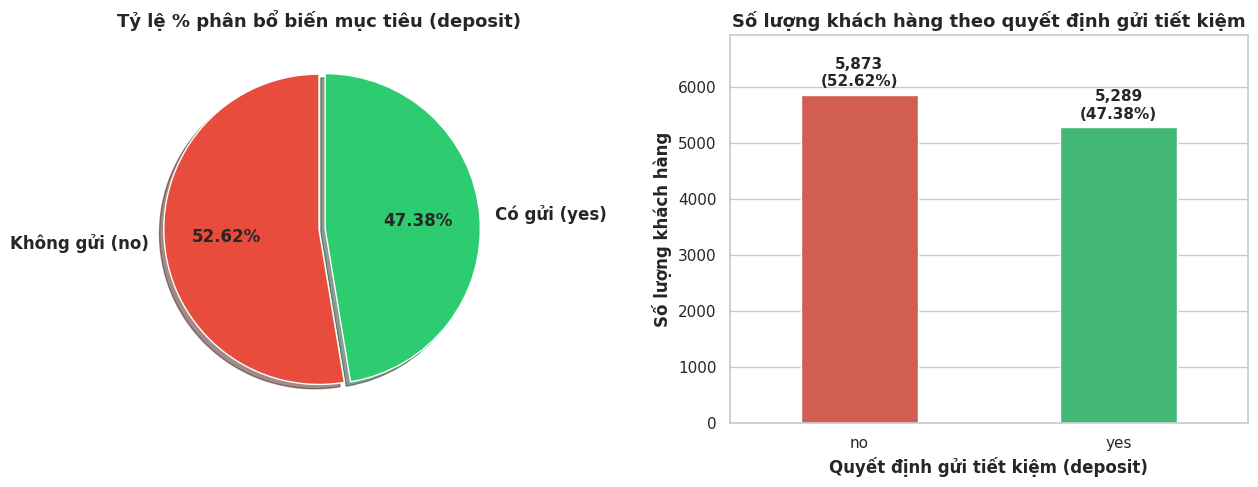

=== BẢNG SỐ LIỆU BIỂU ĐỒ 1: PHÂN BỔ BIẾN MỤC TIÊU (DEPOSIT) ===
         Số lượng khách hàng  Tỷ lệ (%)
deposit                                
no                      5873      52.62
yes                     5289      47.38


In [14]:
# BIỂU ĐỒ 1: TỶ LỆ PHÂN BỔ BIẾN MỤC TIÊU DEPOSIT (YES VS NO)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ['#e74c3c', '#2ecc71']  # Đỏ cho 'no', Xanh lá cho 'yes'
dep_counts = df_clean['deposit'].value_counts()

# 1. Biểu đồ tròn (Pie Chart) thể hiện cơ cấu %
axes[0].pie(
    dep_counts,
    labels=['Không gửi (no)', 'Có gửi (yes)'],
    autopct='%1.2f%%',
    startangle=90,
    colors=colors,
    explode=(0, 0.04),
    shadow=True,
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
axes[0].set_title('Tỷ lệ % phân bổ biến mục tiêu (deposit)')

# 2. Biểu đồ cột (Bar Chart) thể hiện số lượng tuyệt đối và tỷ lệ %
bars = sns.countplot(data=df_clean, x='deposit', order=['no', 'yes'], palette=colors, ax=axes[1], width=0.45)
axes[1].set_title('Số lượng khách hàng theo quyết định gửi tiết kiệm')
axes[1].set_xlabel('Quyết định gửi tiết kiệm (deposit)', fontweight='bold')
axes[1].set_ylabel('Số lượng khách hàng', fontweight='bold')
axes[1].set_ylim(0, max(dep_counts) * 1.18)

# Hiển thị nhãn số lượng và % trực tiếp trên đỉnh cột
for p in bars.patches:
    height = int(p.get_height())
    pct = (height / len(df_clean)) * 100
    axes[1].annotate(
        f'{height:,}\n({pct:.2f}%)',
        (p.get_x() + p.get_width() / 2., height),
        ha='center', va='bottom', fontsize=11, fontweight='bold',
        xytext=(0, 4), textcoords='offset points'
    )

plt.tight_layout()
plt.savefig('figures/bd1_deposit.png', dpi=150, bbox_inches='tight')
plt.show()

# --- XUẤT SỐ LIỆU TÓM TẮT CHO BÁO CÁO ---
summary_chart1 = pd.DataFrame({
    'Số lượng khách hàng': df_clean['deposit'].value_counts(),
    'Tỷ lệ (%)': (df_clean['deposit'].value_counts(normalize=True) * 100).round(2)
})
print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 1: PHÂN BỔ BIẾN MỤC TIÊU (DEPOSIT) ===")
print(summary_chart1)

### Deep Insight – Biểu đồ 1 (mục 3.1: phân bố `deposit`)
**Giả thuyết:** dữ liệu có cân bằng giữa hai lớp yes/no hay không.

- **Số liệu cụ thể:** 5.289 khách đăng ký (yes, 47,38%) và 5.873 khách từ chối (no, 52,62%) trên tổng 11.162 khách.
- **So sánh:** hai lớp chỉ chênh nhau khoảng 5,2 điểm phần trăm, chưa đến mức mất cân bằng.
- **Kết luận giả thuyết:** dữ liệu **khá cân bằng**, không cần kỹ thuật cân bằng lớp; tỷ lệ 47,38% được dùng làm mốc so sánh cho mọi biểu đồ phía sau.
- **Bài học / hành động:** gần một nửa khách được gọi đã đăng ký, nên việc cần tối ưu là chọn đúng nhóm khách và cách tiếp cận để nâng tỷ lệ này, thay vì tăng số cuộc gọi một cách đại trà.

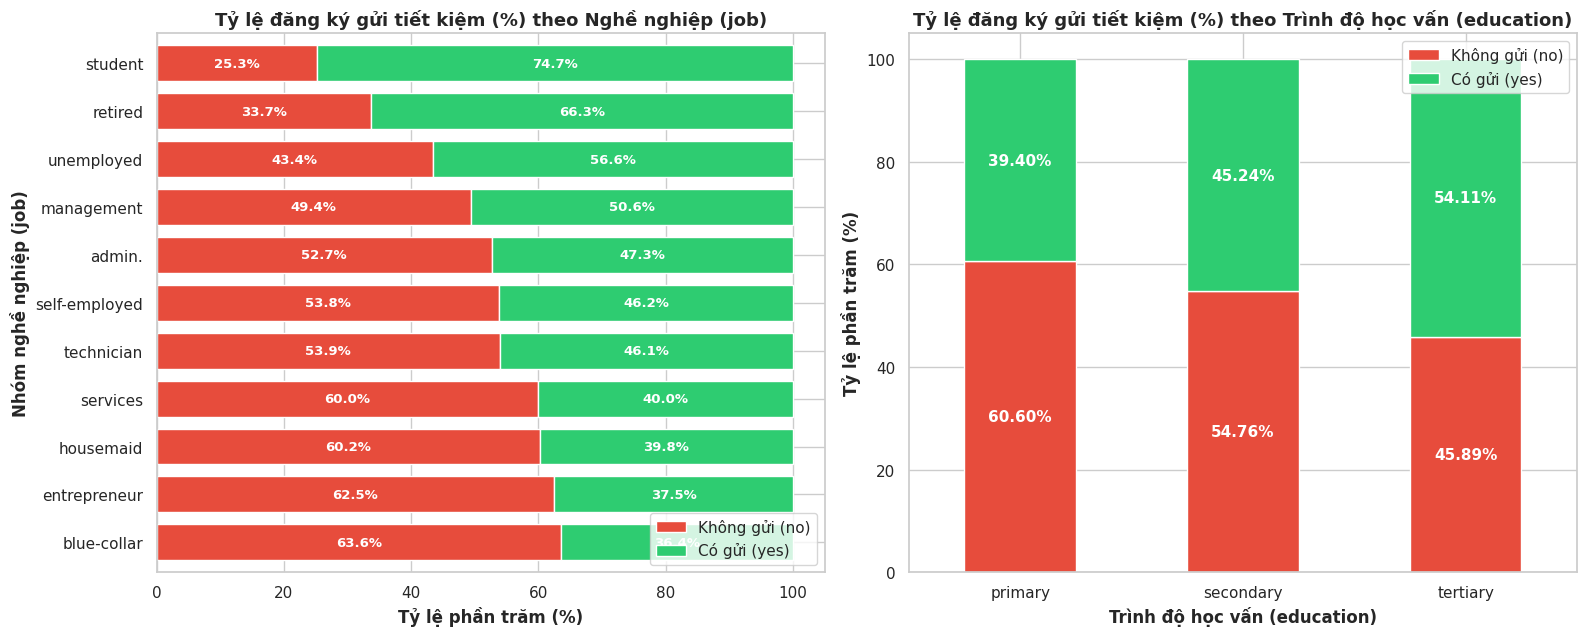

=== BẢNG SỐ LIỆU BIỂU ĐỒ 2A: DEPOSIT THEO NGHỀ NGHIỆP (JOB) ===
               Không gửi - No (SL)  Có gửi - Yes (SL)  Tổng số KH  Tỷ lệ No (%)  Tỷ lệ Yes (%)
job                                                                                           
student                         91                269         360         25.28          74.72
retired                        262                516         778         33.68          66.32
unemployed                     155                202         357         43.42          56.58
management                    1301               1335        2636         49.36          50.64
admin.                         703                631        1334         52.70          47.30
self-employed                  218                187         405         53.83          46.17
technician                     983                840        1823         53.92          46.08
services                       554                369         923         60.02  

In [15]:
# BIỂU ĐỒ 2: TỶ LỆ GỬI TIẾT KIỆM THEO NGHỀ NGHIỆP (JOB) VÀ HỌC VẤN (EDUCATION)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# 1. Stacked Horizontal Bar Chart: Tỷ lệ % deposit theo Nghề nghiệp (job)
job_pct_plot = pd.crosstab(df_clean['job'], df_clean['deposit'], normalize='index') * 100
job_pct_plot = job_pct_plot.sort_values(by='yes', ascending=True)

job_pct_plot[['no', 'yes']].plot(
    kind='barh', stacked=True, color=['#e74c3c', '#2ecc71'], ax=axes[0], width=0.75
)
axes[0].set_title('Tỷ lệ đăng ký gửi tiết kiệm (%) theo Nghề nghiệp (job)')
axes[0].set_xlabel('Tỷ lệ phần trăm (%)', fontweight='bold')
axes[0].set_ylabel('Nhóm nghề nghiệp (job)', fontweight='bold')
axes[0].legend(['Không gửi (no)', 'Có gửi (yes)'], loc='lower right')

# Ghi nhãn % trực tiếp lên thanh biểu đồ
for i, (idx, row) in enumerate(job_pct_plot.iterrows()):
    axes[0].text(row['no'] / 2, i, f"{row['no']:.1f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=9.5)
    axes[0].text(row['no'] + row['yes'] / 2, i, f"{row['yes']:.1f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=9.5)

# 2. Stacked Bar Chart: Tỷ lệ % deposit theo Trình độ học vấn (education)
edu_pct_plot = pd.crosstab(df_clean['education'], df_clean['deposit'], normalize='index') * 100
edu_pct_plot = edu_pct_plot.reindex(['primary', 'secondary', 'tertiary'])

edu_pct_plot[['no', 'yes']].plot(
    kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], ax=axes[1], width=0.5, rot=0
)
axes[1].set_title('Tỷ lệ đăng ký gửi tiết kiệm (%) theo Trình độ học vấn (education)')
axes[1].set_xlabel('Trình độ học vấn (education)', fontweight='bold')
axes[1].set_ylabel('Tỷ lệ phần trăm (%)', fontweight='bold')
axes[1].legend(['Không gửi (no)', 'Có gửi (yes)'], loc='upper right')

for i, (idx, row) in enumerate(edu_pct_plot.iterrows()):
    axes[1].text(i, row['no'] / 2, f"{row['no']:.2f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=11)
    axes[1].text(i, row['no'] + row['yes'] / 2, f"{row['yes']:.2f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('figures/bd2_job_education.png', dpi=150, bbox_inches='tight')
plt.show()

# --- XUẤT SỐ LIỆU TÓM TẮT CHO BÁO CÁO ---
job_ct = pd.crosstab(df_clean['job'], df_clean['deposit'], margins=True, margins_name='Tổng')
job_pct = pd.crosstab(df_clean['job'], df_clean['deposit'], normalize='index') * 100
summary_job = pd.DataFrame({
    'Không gửi - No (SL)': job_ct['no'],
    'Có gửi - Yes (SL)': job_ct['yes'],
    'Tổng số KH': job_ct['Tổng'],
    'Tỷ lệ No (%)': job_pct['no'].round(2),
    'Tỷ lệ Yes (%)': job_pct['yes'].round(2)
}).sort_values(by='Tỷ lệ Yes (%)', ascending=False)

edu_ct = pd.crosstab(df_clean['education'], df_clean['deposit'], margins=True, margins_name='Tổng')
edu_pct = pd.crosstab(df_clean['education'], df_clean['deposit'], normalize='index') * 100
summary_edu = pd.DataFrame({
    'Không gửi - No (SL)': edu_ct['no'],
    'Có gửi - Yes (SL)': edu_ct['yes'],
    'Tổng số KH': edu_ct['Tổng'],
    'Tỷ lệ No (%)': edu_pct['no'].round(2),
    'Tỷ lệ Yes (%)': edu_pct['yes'].round(2)
}).sort_values(by='Tỷ lệ Yes (%)', ascending=False)

print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 2A: DEPOSIT THEO NGHỀ NGHIỆP (JOB) ===")
print(summary_job.to_string())
print("\n=== BẢNG SỐ LIỆU BIỂU ĐỒ 2B: DEPOSIT THEO TRÌNH ĐỘ HỌC VẤN (EDUCATION) ===")
print(summary_edu.to_string())

### Deep Insight – Biểu đồ 2 (H2, H3a: nghề nghiệp và học vấn)
**Giả thuyết:** student, retired cao hơn blue-collar, services; học vấn cao hơn thì tỷ lệ cao hơn.

- **Số liệu cụ thể:** hai nghề cao nhất là student 74,72% (n = 360) và retired 66,32% (n = 778); hai nghề thấp nhất là blue-collar 36,42% (n = 1.944) và entrepreneur 37,50% (n = 328). Theo học vấn: primary 39,40% (n = 1.500), secondary 45,24% (n = 5.973), tertiary 54,11% (n = 3.689).
- **So sánh:** student cao hơn mức chung 47,38% đến 27,34 điểm % và cao hơn blue-collar 38,30 điểm %; retired cao hơn mức chung 18,94 điểm %. Nhóm tertiary cao hơn primary 14,71 điểm %. Các nhóm chính đều có n từ vài trăm trở lên nên đủ tin cậy.
- **Kết luận giả thuyết:** **H2 được ủng hộ** (student, retired vượt xa blue-collar, services); **H3a được ủng hộ** vì tỷ lệ tăng đều theo trình độ học vấn.
- **Bài học / hành động:** ưu tiên gọi student, retired và cả unemployed (56,58%, n = 357); giảm dồn cuộc gọi vào blue-collar (1.944 khách nhưng chỉ 36,42% đăng ký) và nhóm trình độ primary.

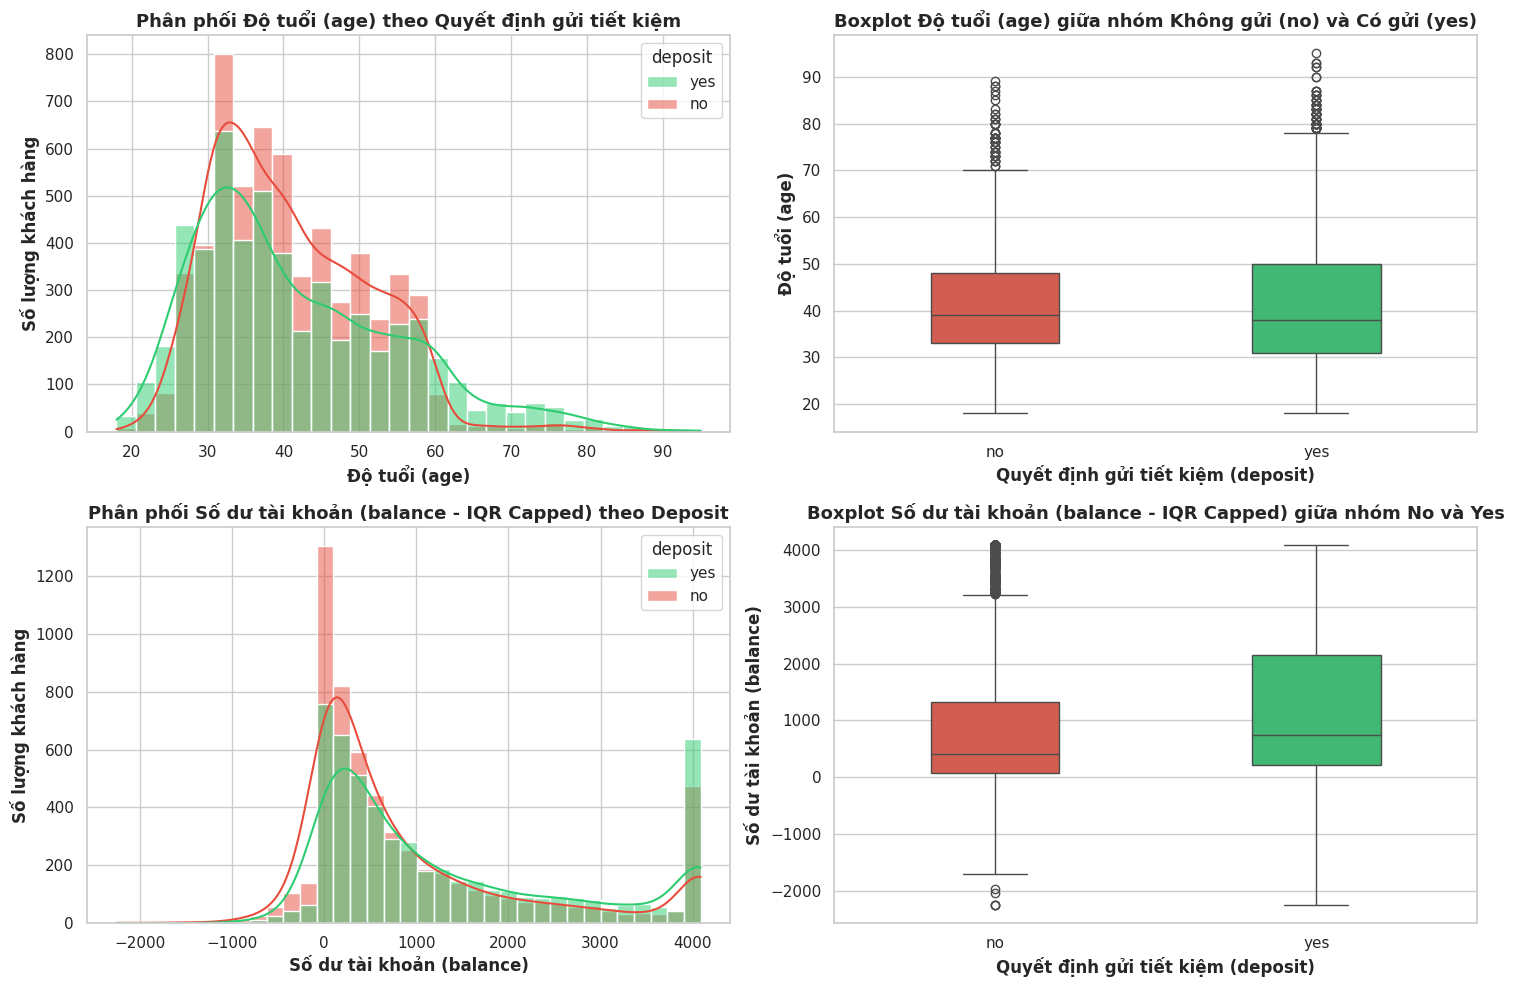

=== BẢNG SỐ LIỆU BIỂU ĐỒ 3A: THỐNG KÊ ĐỘ TUỔI (AGE) & SỐ DƯ GỐC (BALANCE) THEO DEPOSIT ===
          age                            balance                                    
        count  mean median   std min max   count    mean median     std   min    max
deposit                                                                             
no       5873 40.84  39.00 10.26  18  89    5873 1280.23 414.00 2933.41 -6847  66653
yes      5289 41.67  38.00 13.50  18  95    5289 1804.27 733.00 3501.10 -3058  81204

=== BẢNG SỐ LIỆU BIỂU ĐỒ 3B: TỶ LỆ GỬI TIẾT KIỆM THEO NHÓM ĐỘ TUỔI ===
                         No (SL)  Yes (SL)  Tổng KH  Tỷ lệ No (%)  Tỷ lệ Yes (%)
age_group                                                                       
≤ 25 (Gen Z/Sinh viên)       130       320      450         28.89          71.11
26 - 35 (Trẻ)               2052      1869     3921         52.33          47.67
36 - 50 (Trung niên)        2533      1787     4320         58.63          41.37
51 - 60

In [16]:
# BIỂU ĐỒ 3: PHÂN PHỐI ĐỘ TUỔI (AGE) VÀ SỐ DƯ TÀI KHOẢN (BALANCE) THEO DEPOSIT
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
palette_map = {'no': '#e74c3c', 'yes': '#2ecc71'}

# 1. Histogram + KDE cho Độ tuổi (age)
sns.histplot(data=df_clean, x='age', hue='deposit', kde=True, palette=palette_map, ax=axes[0, 0], bins=30, alpha=0.5)
axes[0, 0].set_title('Phân phối Độ tuổi (age) theo Quyết định gửi tiết kiệm')
axes[0, 0].set_xlabel('Độ tuổi (age)', fontweight='bold')
axes[0, 0].set_ylabel('Số lượng khách hàng', fontweight='bold')

# 2. Boxplot cho Độ tuổi (age)
sns.boxplot(data=df_clean, x='deposit', y='age', order=['no', 'yes'], palette=palette_map, ax=axes[0, 1], width=0.4)
axes[0, 1].set_title('Boxplot Độ tuổi (age) giữa nhóm Không gửi (no) và Có gửi (yes)')
axes[0, 1].set_xlabel('Quyết định gửi tiết kiệm (deposit)', fontweight='bold')
axes[0, 1].set_ylabel('Độ tuổi (age)', fontweight='bold')

# 3. Histogram + KDE cho Số dư tài khoản (balance)
# Lưu ý kỹ thuật: Sử dụng df_capped cho biểu đồ balance để tránh bị giá trị cực đại (81,204) kéo giãn trục hoành làm bẹp hình
sns.histplot(data=df_capped, x='balance', hue='deposit', kde=True, palette=palette_map, ax=axes[1, 0], bins=35, alpha=0.5)
axes[1, 0].set_title('Phân phối Số dư tài khoản (balance - IQR Capped) theo Deposit')
axes[1, 0].set_xlabel('Số dư tài khoản (balance)', fontweight='bold')
axes[1, 0].set_ylabel('Số lượng khách hàng', fontweight='bold')

# 4. Boxplot cho Số dư tài khoản (balance)
sns.boxplot(data=df_capped, x='deposit', y='balance', order=['no', 'yes'], palette=palette_map, ax=axes[1, 1], width=0.4)
axes[1, 1].set_title('Boxplot Số dư tài khoản (balance - IQR Capped) giữa nhóm No và Yes')
axes[1, 1].set_xlabel('Quyết định gửi tiết kiệm (deposit)', fontweight='bold')
axes[1, 1].set_ylabel('Số dư tài khoản (balance)', fontweight='bold')

plt.tight_layout()
plt.savefig('figures/bd3_age_balance.png', dpi=150, bbox_inches='tight')
plt.show()

# --- XUẤT SỐ LIỆU TÓM TẮT CHO BÁO CÁO ---
print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 3A: THỐNG KÊ ĐỘ TUỔI (AGE) & SỐ DƯ GỐC (BALANCE) THEO DEPOSIT ===")
summary_age_bal_raw = df_clean.groupby('deposit')[['age', 'balance']].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)
print(summary_age_bal_raw.to_string())

# Thống kê thêm tỷ lệ gửi tiết kiệm theo nhóm độ tuổi để sinh viên kinh tế có số liệu phân tích sâu
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[0, 25, 35, 50, 60, 100],
    labels=['≤ 25 (Gen Z/Sinh viên)', '26 - 35 (Trẻ)', '36 - 50 (Trung niên)', '51 - 60 (Tiền hưu trí)', '> 60 (Cao tuổi/Hưu trí)']
)
age_grp_ct = pd.crosstab(df_clean['age_group'], df_clean['deposit'])
age_grp_pct = pd.crosstab(df_clean['age_group'], df_clean['deposit'], normalize='index') * 100
summary_age_grp = pd.DataFrame({
    'No (SL)': age_grp_ct['no'],
    'Yes (SL)': age_grp_ct['yes'],
    'Tổng KH': age_grp_ct['no'] + age_grp_ct['yes'],
    'Tỷ lệ No (%)': age_grp_pct['no'].round(2),
    'Tỷ lệ Yes (%)': age_grp_pct['yes'].round(2)
})
print("\n=== BẢNG SỐ LIỆU BIỂU ĐỒ 3B: TỶ LỆ GỬI TIẾT KIỆM THEO NHÓM ĐỘ TUỔI ===")
print(summary_age_grp.to_string())
df_clean.drop(columns=['age_group'], inplace=True)  # Xóa cột phụ sau khi in xong

### Deep Insight – Biểu đồ 3 (H1, H4: tuổi và số dư)
**Giả thuyết:** khách lớn tuổi gửi nhiều hơn; số dư cao hơn thì gửi nhiều hơn.

- **Số liệu cụ thể:** theo nhóm tuổi: ≤ 25 là 71,11% (n = 450); 26-35 là 47,67% (n = 3.921); 36-50 là 41,37% (n = 4.320); 51-60 là 43,60% (n = 1.860); > 60 là 82,16% (n = 611). Tuổi trung bình nhóm yes 41,67 và nhóm no 40,84. Về số dư, trung vị nhóm yes là 733 so với 414 của nhóm no (trung bình 1.804 so với 1.280).
- **So sánh:** nhóm > 60 cao hơn mức chung 34,78 điểm %, nhóm ≤ 25 cao hơn 23,73 điểm %, trong khi nhóm 36-50 thấp hơn 6,01 điểm %. Tuổi trung bình hai nhóm chỉ chênh 0,83 năm, nên tuổi trung bình không phản ánh được sự khác biệt này. Trung vị số dư nhóm yes gấp khoảng 1,8 lần nhóm no; vì số dư lệch phải nên dùng trung vị thay cho trung bình.
- **Kết luận giả thuyết:** **H1 được ủng hộ một phần:** tỷ lệ có dạng **chữ U** (cao ở nhóm trẻ ≤ 25 và nhóm > 60), không phải "tuổi càng cao càng gửi". **H4 được ủng hộ** theo trung vị số dư.
- **Bài học / hành động:** ưu tiên nhóm > 60 và nhóm ≤ 25; nhóm 36-50 đông nhất (4.320 khách) nhưng tỷ lệ thấp nhất nên cần kịch bản tư vấn riêng thay vì gọi đại trà.

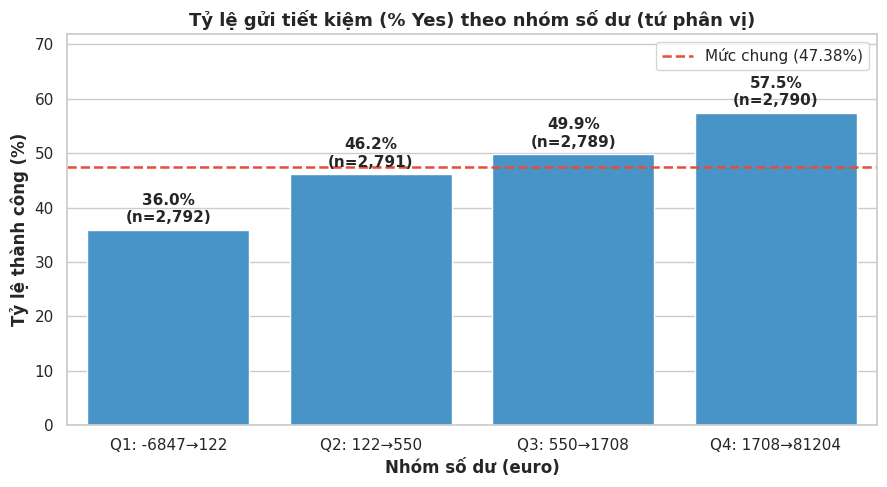

=== BẢNG SỐ LIỆU BIỂU ĐỒ 3C: TỶ LỆ GỬI TIẾT KIỆM THEO NHÓM SỐ DƯ ===
                Không gửi - No (SL)  Có gửi - Yes (SL)  Tổng KH  Tỷ lệ Yes (%)  Chênh so với mức chung (điểm %)
balance_group                                                                                                  
Q1: -6847→122                  1788               1004     2792          35.96                           -11.42
Q2: 122→550                    1501               1290     2791          46.22                            -1.16
Q3: 550→1708                   1398               1391     2789          49.87                             2.49
Q4: 1708→81204                 1186               1604     2790          57.49                            10.11


In [17]:
# BIỂU ĐỒ 3C: TỶ LỆ GỬI TIẾT KIỆM THEO 4 NHÓM SỐ DƯ (TỨ PHÂN VỊ)  -> H4
edges = df_clean['balance'].quantile([0, 0.25, 0.5, 0.75, 1]).values
df_clean['balance_group'] = pd.cut(df_clean['balance'], bins=edges, include_lowest=True,
                                   labels=[f"Q{i+1}: {int(edges[i])}→{int(edges[i+1])}" for i in range(4)])
summary_bal = summary_table('balance_group')

fig, ax = plt.subplots(figsize=(9, 5))
bars = sns.barplot(x=summary_bal.index.astype(str), y=summary_bal['Tỷ lệ Yes (%)'], color='#3498db', ax=ax)
ax.axhline(overall_rate, color='#e74c3c', linestyle='--', linewidth=1.8, label=f'Mức chung ({overall_rate:.2f}%)')
for i, (r, n) in enumerate(zip(summary_bal['Tỷ lệ Yes (%)'], summary_bal['Tổng KH'])):
    ax.annotate(f'{r:.1f}%\n(n={n:,})', (i, r), ha='center', va='bottom', fontweight='bold', xytext=(0, 3), textcoords='offset points')
ax.set_title('Tỷ lệ gửi tiết kiệm (% Yes) theo nhóm số dư (tứ phân vị)')
ax.set_xlabel('Nhóm số dư (euro)', fontweight='bold'); ax.set_ylabel('Tỷ lệ thành công (%)', fontweight='bold')
ax.set_ylim(0, summary_bal['Tỷ lệ Yes (%)'].max() * 1.25); ax.legend()
plt.tight_layout(); plt.savefig('figures/bd3c_balance_nhom.png', dpi=150, bbox_inches='tight'); plt.show()

print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 3C: TỶ LỆ GỬI TIẾT KIỆM THEO NHÓM SỐ DƯ ===")
print(summary_bal.to_string())
df_clean.drop(columns=['balance_group'], inplace=True)

### Deep Insight – Biểu đồ 3C (H4: nhóm số dư)
**Giả thuyết:** số dư cao hơn thì tỷ lệ gửi tiền cao hơn.

- **Số liệu cụ thể:** theo tứ phân vị số dư: Q1 (từ -6.847 đến 122) là 35,96% (n = 2.792); Q2 (122 đến 550) là 46,22% (n = 2.791); Q3 (550 đến 1.708) là 49,87% (n = 2.789); Q4 (1.708 đến 81.204) là 57,49% (n = 2.790).
- **So sánh:** tỷ lệ tăng đều qua từng nhóm; Q4 cao hơn Q1 là 21,53 điểm %, Q1 thấp hơn mức chung 11,42 điểm % và Q4 cao hơn mức chung 10,11 điểm %. Bốn nhóm có cỡ mẫu gần bằng nhau (khoảng 2.790 khách) nên so sánh đáng tin cậy.
- **Kết luận giả thuyết:** **H4 được ủng hộ rõ rệt:** số dư càng cao thì khả năng gửi tiền càng cao.
- **Bài học / hành động:** ưu tiên khách có số dư trên 1.708 euro (nhóm Q4); với khách số dư thấp (từ 122 euro trở xuống) tỷ lệ chỉ 35,96%, nên cân nhắc giảm cường độ gọi hoặc đổi sản phẩm phù hợp hơn.

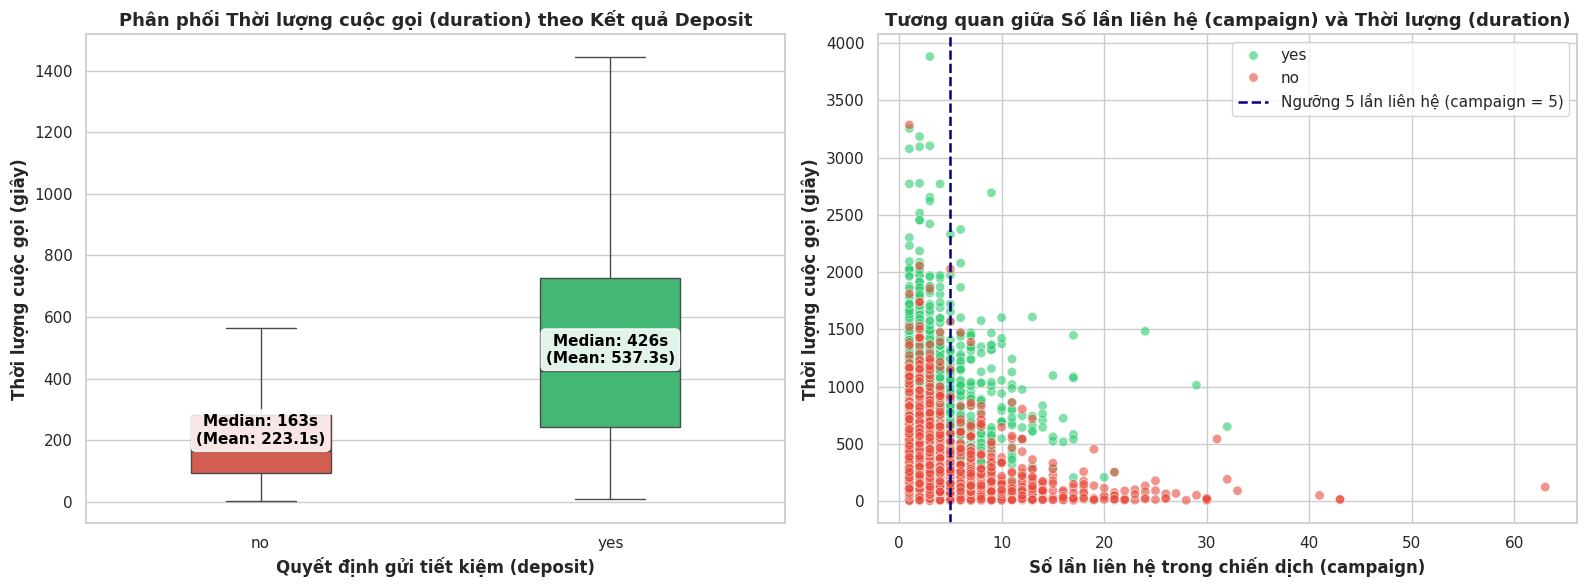

=== BẢNG SỐ LIỆU BIỂU ĐỒ 4A: THỐNG KÊ DURATION & CAMPAIGN THEO DEPOSIT ===
        duration                                campaign                         
           count   mean median    std min   max    count mean median  std min max
deposit                                                                          
no          5873 223.13 163.00 208.58   2  3284     5873 2.84   2.00 3.24   1  63
yes         5289 537.29 426.00 392.53   8  3881     5289 2.14   2.00 1.92   1  32

=== BẢNG SỐ LIỆU BIỂU ĐỒ 4B: TỶ LỆ CHỐT ĐƠN THEO NHÓM THỜI LƯỢNG CUỘC GỌI ===
                        No (SL)  Yes (SL)  Tổng cuộc gọi  Tỷ lệ Yes (%)
duration_group                                                         
≤ 3 phút (≤180s)           3227       709           3936          18.01
3 - 5 phút (181-300s)      1312      1122           2434          46.10
5 - 10 phút (301-600s)     1015      1625           2640          61.55
> 10 phút (>600s)           319      1833           2152          85.18

===

In [18]:
# BIỂU ĐỒ 4: THỜI LƯỢNG CUỘC GỌI (DURATION), SỐ LẦN LIÊN HỆ (CAMPAIGN) & DEPOSIT
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot Thời lượng cuộc gọi (duration) theo kết quả deposit
sns.boxplot(
    data=df_clean, x='deposit', y='duration', order=['no', 'yes'],
    palette=palette_map, ax=axes[0], width=0.4, showfliers=False
)
axes[0].set_title('Phân phối Thời lượng cuộc gọi (duration) theo Kết quả Deposit')
axes[0].set_xlabel('Quyết định gửi tiết kiệm (deposit)', fontweight='bold')
axes[0].set_ylabel('Thời lượng cuộc gọi (giây)', fontweight='bold')

# Hiển thị nhãn Trung vị (Median) và Trung bình (Mean) trực tiếp lên Boxplot
medians = df_clean.groupby('deposit')['duration'].median()
means = df_clean.groupby('deposit')['duration'].mean()
for i, dep in enumerate(['no', 'yes']):
    axes[0].text(
        i, medians[dep] + 15,
        f'Median: {medians[dep]:.0f}s\n(Mean: {means[dep]:.1f}s)',
        ha='center', va='bottom', fontweight='bold', color='black',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85)
    )

# 2. Scatter Plot giữa Số lần gọi (campaign) và Thời lượng (duration)
sns.scatterplot(
    data=df_clean, x='campaign', y='duration', hue='deposit',
    palette=palette_map, alpha=0.6, s=45, ax=axes[1]
)
axes[1].axvline(x=5, color='navy', linestyle='--', linewidth=1.8, label='Ngưỡng 5 lần liên hệ (campaign = 5)')
axes[1].set_title('Tương quan giữa Số lần liên hệ (campaign) và Thời lượng (duration)')
axes[1].set_xlabel('Số lần liên hệ trong chiến dịch (campaign)', fontweight='bold')
axes[1].set_ylabel('Thời lượng cuộc gọi (giây)', fontweight='bold')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig('figures/bd4_duration_campaign.png', dpi=150, bbox_inches='tight')
plt.show()

# --- XUẤT SỐ LIỆU TÓM TẮT CHO BÁO CÁO ---
print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 4A: THỐNG KÊ DURATION & CAMPAIGN THEO DEPOSIT ===")
summary_dur_camp = df_clean.groupby('deposit')[['duration', 'campaign']].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)
print(summary_dur_camp.to_string())

# Thống kê tỷ lệ thành công theo nhóm thời lượng cuộc gọi & số lần gọi
df_clean['duration_group'] = pd.cut(
    df_clean['duration'],
    bins=[0, 180, 300, 600, 5000],
    labels=['≤ 3 phút (≤180s)', '3 - 5 phút (181-300s)', '5 - 10 phút (301-600s)', '> 10 phút (>600s)']
)
dur_ct = pd.crosstab(df_clean['duration_group'], df_clean['deposit'])
dur_pct = pd.crosstab(df_clean['duration_group'], df_clean['deposit'], normalize='index') * 100
summary_dur_grp = pd.DataFrame({
    'No (SL)': dur_ct['no'],
    'Yes (SL)': dur_ct['yes'],
    'Tổng cuộc gọi': dur_ct['no'] + dur_ct['yes'],
    'Tỷ lệ Yes (%)': dur_pct['yes'].round(2)
})
print("\n=== BẢNG SỐ LIỆU BIỂU ĐỒ 4B: TỶ LỆ CHỐT ĐƠN THEO NHÓM THỜI LƯỢNG CUỘC GỌI ===")
print(summary_dur_grp.to_string())

df_clean['campaign_group'] = pd.cut(
    df_clean['campaign'],
    bins=[0, 1, 3, 5, 100],
    labels=['1 lần', '2 - 3 lần', '4 - 5 lần', '> 5 lần (Gọi quá nhiều)']
)
camp_ct = pd.crosstab(df_clean['campaign_group'], df_clean['deposit'])
camp_pct = pd.crosstab(df_clean['campaign_group'], df_clean['deposit'], normalize='index') * 100
summary_camp_grp = pd.DataFrame({
    'No (SL)': camp_ct['no'],
    'Yes (SL)': camp_ct['yes'],
    'Tổng KH': camp_ct['no'] + camp_ct['yes'],
    'Tỷ lệ Yes (%)': camp_pct['yes'].round(2)
})
print("\n=== BẢNG SỐ LIỆU BIỂU ĐỒ 4C: TỶ LỆ CHỐT ĐƠN THEO SỐ LẦN LIÊN HỆ (CAMPAIGN) ===")
print(summary_camp_grp.to_string())
df_clean.drop(columns=['duration_group', 'campaign_group'], inplace=True)

### Deep Insight – Biểu đồ 4 (H8, H9: thời lượng và số lần gọi)
**Giả thuyết:** cuộc gọi dài hơn thì tỷ lệ cao hơn; gọi nhiều lần thì tỷ lệ giảm.

- **Số liệu cụ thể:** theo thời lượng: ≤ 3 phút là 18,01% (n = 3.936); 3-5 phút là 46,10% (n = 2.434); 5-10 phút là 61,55% (n = 2.640); > 10 phút là 85,18% (n = 2.152). Trung vị thời lượng nhóm yes là 426 giây so với 163 giây của nhóm no. Theo số lần gọi: 1 lần 53,38%; 2-3 lần 46,42%; 4-5 lần 39,69%; > 5 lần 29,21%.
- **So sánh:** tỷ lệ nhóm > 10 phút cao hơn nhóm ≤ 3 phút tới 67,17 điểm %, và trung vị thời lượng nhóm yes gấp khoảng 2,6 lần nhóm no. Về số lần gọi, tỷ lệ giảm 24,17 điểm % từ 1 lần xuống trên 5 lần. Đường đứng `campaign = 5` trên biểu đồ phân tán là mốc tham chiếu; ở biểu đồ 4D, tại 5 lần gọi tỷ lệ là 36,77%, thấp hơn mức chung 10,61 điểm %.
- **Kết luận giả thuyết:** **H8 được ủng hộ mạnh** nhưng `duration` chỉ biết **sau** cuộc gọi nên là kết quả chứ không phải nguyên nhân; **H9 được ủng hộ** vì tỷ lệ giảm dần khi gọi nhiều lần.
- **Bài học / hành động:** không dùng `duration` để chọn khách trước khi gọi; chỉ dùng như tín hiệu theo dõi (cuộc gọi kéo dài trên 5 phút thường là khách quan tâm). Nên giới hạn số lần gọi mỗi khách để tránh tốn chi phí và làm phiền khách.

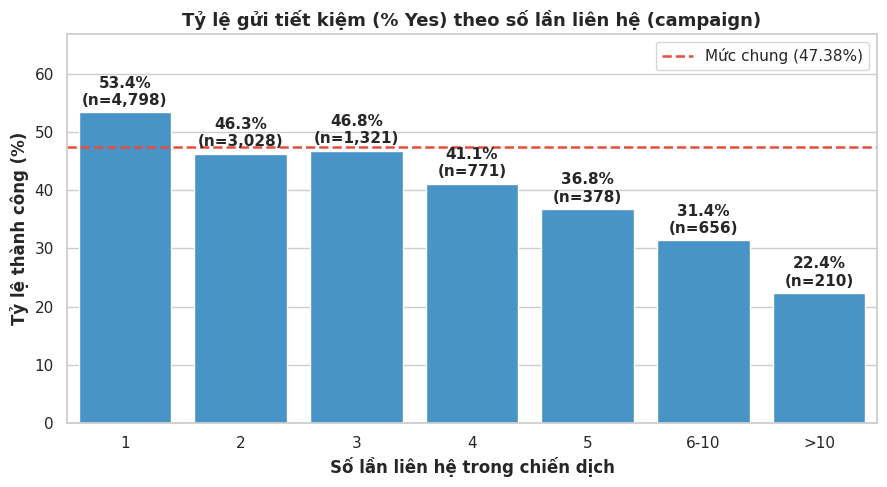

=== BẢNG SỐ LIỆU BIỂU ĐỒ 4D: TỶ LỆ GỬI TIẾT KIỆM THEO SỐ LẦN GỌI ===
                Không gửi - No (SL)  Có gửi - Yes (SL)  Tổng KH  Tỷ lệ Yes (%)  Chênh so với mức chung (điểm %)
campaign_group                                                                                                 
1                              2237               2561     4798          53.38                             6.00
2                              1627               1401     3028          46.27                            -1.11
3                               703                618     1321          46.78                            -0.60
4                               454                317      771          41.12                            -6.26
5                               239                139      378          36.77                           -10.61
6-10                            450                206      656          31.40                           -15.98
>10                             163

In [19]:
# BIỂU ĐỒ 4D: TỶ LỆ GỬI TIẾT KIỆM THEO TỪNG MỨC SỐ LẦN GỌI VÀ NGƯỠNG DỪNG ĐỀ XUẤT  -> H9
df_clean['campaign_group'] = pd.cut(df_clean['campaign'], bins=[0, 1, 2, 3, 4, 5, 10, 100],
                                    labels=['1', '2', '3', '4', '5', '6-10', '>10'])
summary_camp = summary_table('campaign_group')

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=summary_camp.index.astype(str), y=summary_camp['Tỷ lệ Yes (%)'], color='#3498db', ax=ax)
ax.axhline(overall_rate, color='#e74c3c', linestyle='--', linewidth=1.8, label=f'Mức chung ({overall_rate:.2f}%)')
for i, (r, n) in enumerate(zip(summary_camp['Tỷ lệ Yes (%)'], summary_camp['Tổng KH'])):
    ax.annotate(f'{r:.1f}%\n(n={n:,})', (i, r), ha='center', va='bottom', fontweight='bold', xytext=(0, 3), textcoords='offset points')
ax.set_title('Tỷ lệ gửi tiết kiệm (% Yes) theo số lần liên hệ (campaign)')
ax.set_xlabel('Số lần liên hệ trong chiến dịch', fontweight='bold'); ax.set_ylabel('Tỷ lệ thành công (%)', fontweight='bold')
ax.set_ylim(0, summary_camp['Tỷ lệ Yes (%)'].max() * 1.25); ax.legend()
plt.tight_layout(); plt.savefig('figures/bd4d_campaign_nguong_dung.png', dpi=150, bbox_inches='tight'); plt.show()

print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 4D: TỶ LỆ GỬI TIẾT KIỆM THEO SỐ LẦN GỌI ===")
print(summary_camp.to_string())

# Tiêu chí ngưỡng dừng: nhóm số lần gọi đầu tiên có tỷ lệ thấp hơn mức chung ít nhất GAP điểm %
GAP = 5
below_avg = summary_camp[summary_camp['Tỷ lệ Yes (%)'] < overall_rate - GAP]
print(f"\n👉 Nhóm số lần gọi đầu tiên thấp hơn mức chung ≥ {GAP} điểm %:",
      below_avg.index[0] if len(below_avg) else "không có")
df_clean.drop(columns=['campaign_group'], inplace=True)

### Deep Insight – Biểu đồ 4D (H9: ngưỡng dừng số lần gọi)
**Giả thuyết:** gọi càng nhiều lần thì tỷ lệ càng giảm.

- **Số liệu cụ thể:** theo từng mức số lần gọi: 1 lần 53,38% (n = 4.798); 2 lần 46,27% (n = 3.028); 3 lần 46,78% (n = 1.321); 4 lần 41,12% (n = 771); 5 lần 36,77% (n = 378); 6-10 lần 31,40% (n = 656); trên 10 lần 22,38% (n = 210).
- **So sánh:** tỷ lệ giảm gần đơn điệu (riêng 2 và 3 lần gần như ngang nhau, chênh 0,51 điểm %). Nhóm trên 10 lần thấp hơn mức chung tới 25,00 điểm %, nhưng chỉ có 210 khách nên cần thận trọng khi khái quát.
- **Kết luận giả thuyết:** **H9 được ủng hộ.** Với tiêu chí "thấp hơn mức chung ít nhất 5 điểm %", nhóm đầu tiên vượt tiêu chí là **4 lần gọi** (41,12%, thấp hơn mức chung 6,26 điểm %).
- **Bài học / hành động:** đặt ngưỡng dừng **tối đa 3 lần gọi mỗi khách**; từ lần thứ 4 trở đi hiệu quả mỗi cuộc gọi thấp hơn mức chung rõ rệt.

*Đề xuất cho Giai đoạn 4:* ngưỡng dừng tối đa 3 lần gọi mỗi khách (tiêu chí: thấp hơn mức chung ít nhất 5 điểm %).

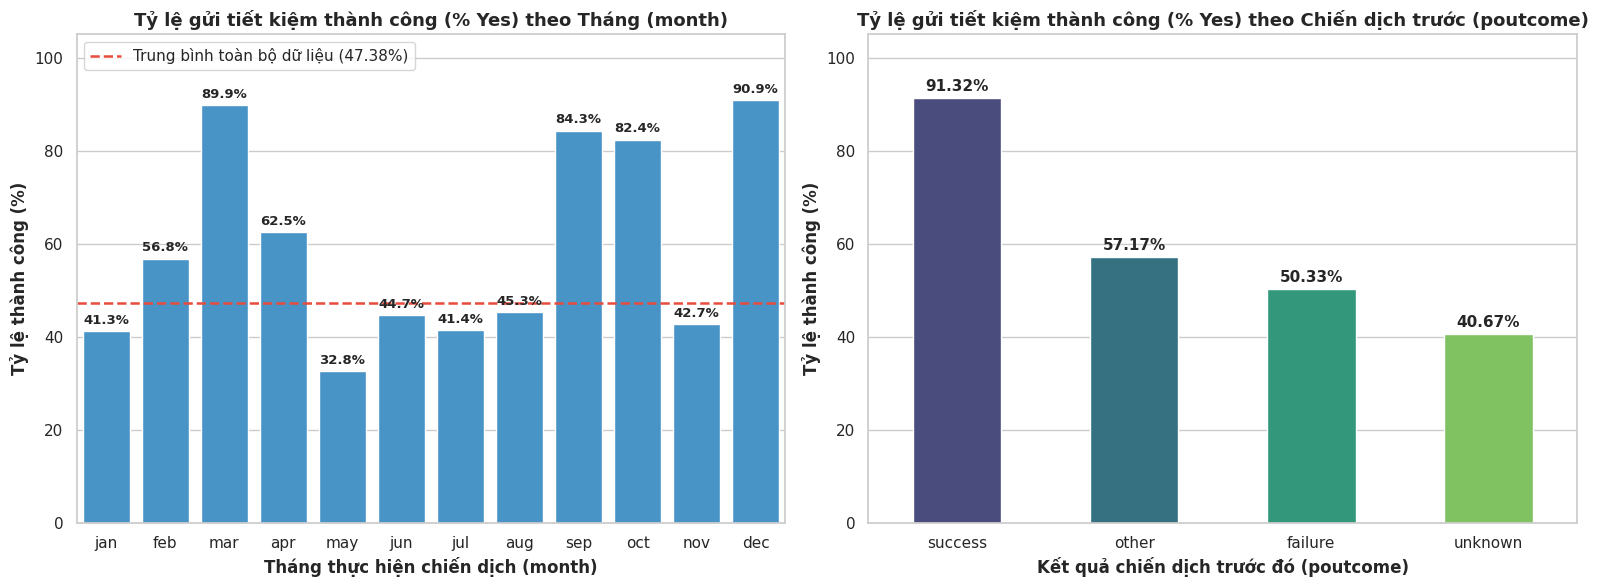

=== BẢNG SỐ LIỆU BIỂU ĐỒ 5A: HIỆU QUẢ CHIẾN DỊCH THEO THÁNG (MONTH) ===
       Không gửi - No (SL)  Có gửi - Yes (SL)  Tổng cuộc gọi  Tỷ lệ cuộc gọi toàn chiến dịch (%)  Tỷ lệ chốt đơn Yes (%)
month                                                                                                                   
jan                    202                142            344                                3.08                   41.28
feb                    335                441            776                                6.95                   56.83
mar                     28                248            276                                2.47                   89.86
apr                    346                577            923                                8.27                   62.51
may                   1899                925           2824                               25.30                   32.75
jun                    676                546           1222                     

In [20]:
# BIỂU ĐỒ 5: TỶ LỆ THÀNH CÔNG THEO THÁNG (MONTH) & KẾT QUẢ CHIẾN DỊCH TRƯỚC (POUTCOME)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Biểu đồ cột: Tỷ lệ thành công (% Yes) theo Tháng (month)
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_pct = pd.crosstab(df_clean['month'], df_clean['deposit'], normalize='index').reindex(month_order) * 100

bars_m = sns.barplot(x=month_pct.index, y=month_pct['yes'], color='#3498db', ax=axes[0])
overall_pct = (df_clean['deposit'] == 'yes').mean() * 100   # tỷ lệ gửi tiền chung tính trực tiếp từ dữ liệu
axes[0].axhline(y=overall_pct, color='#e74c3c', linestyle='--', linewidth=1.8, label=f'Trung bình toàn bộ dữ liệu ({overall_pct:.2f}%)')
axes[0].set_title('Tỷ lệ gửi tiết kiệm thành công (% Yes) theo Tháng (month)')
axes[0].set_xlabel('Tháng thực hiện chiến dịch (month)', fontweight='bold')
axes[0].set_ylabel('Tỷ lệ thành công (%)', fontweight='bold')
axes[0].set_ylim(0, 105)
axes[0].legend(loc='upper left')

for p in bars_m.patches:
    h = p.get_height()
    axes[0].annotate(
        f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h),
        ha='center', va='bottom', fontsize=9.5, fontweight='bold',
        xytext=(0, 3), textcoords='offset points'
    )

# 2. Biểu đồ cột: Tỷ lệ thành công (% Yes) theo Kết quả chiến dịch trước (poutcome)
pout_pct = pd.crosstab(df_clean['poutcome'], df_clean['deposit'], normalize='index') * 100
pout_pct = pout_pct.sort_values(by='yes', ascending=False)

bars_p = sns.barplot(x=pout_pct.index, y=pout_pct['yes'], palette='viridis', ax=axes[1], width=0.5)
axes[1].set_title('Tỷ lệ gửi tiết kiệm thành công (% Yes) theo Chiến dịch trước (poutcome)')
axes[1].set_xlabel('Kết quả chiến dịch trước đó (poutcome)', fontweight='bold')
axes[1].set_ylabel('Tỷ lệ thành công (%)', fontweight='bold')
axes[1].set_ylim(0, 105)

for p in bars_p.patches:
    h = p.get_height()
    axes[1].annotate(
        f'{h:.2f}%', (p.get_x() + p.get_width() / 2., h),
        ha='center', va='bottom', fontsize=11, fontweight='bold',
        xytext=(0, 3), textcoords='offset points'
    )

plt.tight_layout()
plt.savefig('figures/bd5_month_poutcome.png', dpi=150, bbox_inches='tight')
plt.show()

# --- XUẤT SỐ LIỆU TÓM TẮT CHO BÁO CÁO ---
month_ct = pd.crosstab(df_clean['month'], df_clean['deposit']).reindex(month_order)
summary_month = pd.DataFrame({
    'Không gửi - No (SL)': month_ct['no'],
    'Có gửi - Yes (SL)': month_ct['yes'],
    'Tổng cuộc gọi': month_ct['no'] + month_ct['yes'],
    'Tỷ lệ cuộc gọi toàn chiến dịch (%)': ((month_ct['no'] + month_ct['yes']) / len(df_clean) * 100).round(2),
    'Tỷ lệ chốt đơn Yes (%)': month_pct['yes'].round(2)
})
print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 5A: HIỆU QUẢ CHIẾN DỊCH THEO THÁNG (MONTH) ===")
print(summary_month.to_string())

pout_ct = pd.crosstab(df_clean['poutcome'], df_clean['deposit'])
pout_pct_full = pd.crosstab(df_clean['poutcome'], df_clean['deposit'], normalize='index') * 100
summary_poutcome = pd.DataFrame({
    'Không gửi - No (SL)': pout_ct['no'],
    'Có gửi - Yes (SL)': pout_ct['yes'],
    'Tổng KH': pout_ct['no'] + pout_ct['yes'],
    'Tỷ lệ No (%)': pout_pct_full['no'].round(2),
    'Tỷ lệ Yes (%)': pout_pct_full['yes'].round(2)
}).sort_values(by='Tỷ lệ Yes (%)', ascending=False)
print("\n=== BẢNG SỐ LIỆU BIỂU ĐỒ 5B: HIỆU QUẢ THEO KẾT QUẢ CHIẾN DỊCH TRƯỚC (POUTCOME) ===")
print(summary_poutcome.to_string())

### Deep Insight – Biểu đồ 5 (H6, H10: tháng và kết quả chiến dịch trước)
**Giả thuyết:** tỷ lệ khác nhau rõ giữa các tháng (tháng ít cuộc gọi kém tin cậy); `poutcome = success` cao hơn rất nhiều.

- **Số liệu cụ thể:** tháng 5 có 2.824 cuộc gọi (25,30% toàn chiến dịch) nhưng chỉ 32,75% đăng ký. Các tháng mar (89,86%, n = 276), sep (84,33%, n = 319), oct (82,40%, n = 392) và dec (90,91%, n = 110) đạt tỷ lệ rất cao; apr 62,51% (n = 923) và feb 56,83% (n = 776) cũng vượt mức chung. Theo kết quả chiến dịch trước: success 91,32% (n = 1.071); other 57,17% (n = 537); failure 50,33% (n = 1.228); unknown 40,67% (n = 8.326).
- **So sánh:** tháng 5 thấp hơn mức chung 14,63 điểm %. Nhóm success cao hơn mức chung 43,94 điểm % và cao hơn nhóm unknown 50,65 điểm %; ngay cả nhóm failure vẫn cao hơn mức chung 2,95 điểm %. Bốn tháng mar, sep, oct, dec chỉ có từ 110 đến 392 cuộc gọi nên kém tin cậy hơn apr và feb.
- **Kết luận giả thuyết:** **H6 được ủng hộ** (tỷ lệ khác biệt rõ giữa các tháng, kèm lưu ý về tháng ít dữ liệu); **H10 được ủng hộ rất mạnh.**
- **Bài học / hành động:** không dồn quá nhiều cuộc gọi vào tháng 5; ưu tiên gọi lại khách từng success ở chiến dịch trước, đồng thời cân nhắc tăng nguồn lực cho các tháng apr, feb và những tháng cuối năm sau khi kiểm chứng thêm bằng dữ liệu nhiều năm.

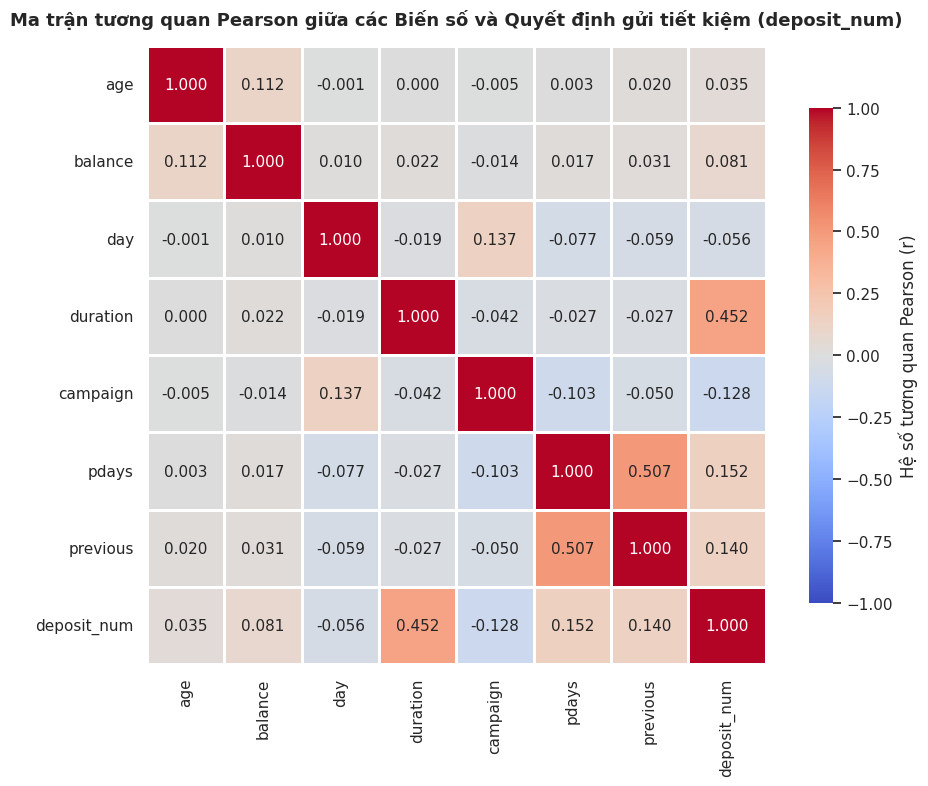

=== BẢNG SỐ LIỆU BIỂU ĐỒ 6A: MA TRẬN TƯƠNG QUAN PEARSON CHI TIẾT ===
              age  balance   day  duration  campaign  pdays  previous  deposit_num
age          1.00     0.11 -0.00      0.00     -0.01   0.00      0.02         0.03
balance      0.11     1.00  0.01      0.02     -0.01   0.02      0.03         0.08
day         -0.00     0.01  1.00     -0.02      0.14  -0.08     -0.06        -0.06
duration     0.00     0.02 -0.02      1.00     -0.04  -0.03     -0.03         0.45
campaign    -0.01    -0.01  0.14     -0.04      1.00  -0.10     -0.05        -0.13
pdays        0.00     0.02 -0.08     -0.03     -0.10   1.00      0.51         0.15
previous     0.02     0.03 -0.06     -0.03     -0.05   0.51      1.00         0.14
deposit_num  0.03     0.08 -0.06      0.45     -0.13   0.15      0.14         1.00

=== BẢNG SỐ LIỆU BIỂU ĐỒ 6B: XẾP HẠNG MỨC ĐỘ TƯƠNG QUAN VỚI BIẾN MỤC TIÊU (DEPOSIT_NUM) ===
          Hệ số tương quan (r) Chiều hướng tác động
duration                  0.45      Thu

In [21]:
# BIỂU ĐỒ 6: MA TRẬN TƯƠNG QUAN PEARSON (CORRELATION HEATMAP) GIỮA CÁC BIẾN SỐ
# ==============================================================================
plt.figure(figsize=(10, 8))

# Tạo bản sao để mã hóa biến mục tiêu deposit sang dạng số (0/1) nhằm tính tương quan với các biến số khác
df_corr = df_clean.copy()
df_corr['deposit_num'] = df_corr['deposit'].map({'no': 0, 'yes': 1})

num_cols_corr = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'deposit_num']
corr_matrix = df_corr[num_cols_corr].corr()

# Vẽ Heatmap hiển thị hệ số tương quan Pearson (r)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    vmin=-1, vmax=1, center=0,
    linewidths=1,
    square=True,
    cbar_kws={'shrink': 0.8, 'label': 'Hệ số tương quan Pearson (r)'}
)
plt.title('Ma trận tương quan Pearson giữa các Biến số và Quyết định gửi tiết kiệm (deposit_num)', pad=15)
plt.tight_layout()
plt.savefig('figures/bd6_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# --- XUẤT SỐ LIỆU TÓM TẮT CHO BÁO CÁO ---
print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 6A: MA TRẬN TƯƠNG QUAN PEARSON CHI TIẾT ===")
print(corr_matrix.round(4).to_string())

print("\n=== BẢNG SỐ LIỆU BIỂU ĐỒ 6B: XẾP HẠNG MỨC ĐỘ TƯƠNG QUAN VỚI BIẾN MỤC TIÊU (DEPOSIT_NUM) ===")
target_corr = corr_matrix['deposit_num'].drop('deposit_num').sort_values(ascending=False)
summary_corr_target = pd.DataFrame({
    'Hệ số tương quan (r)': target_corr.round(4),
    'Chiều hướng tác động': ['Thuận chiều (+)' if x > 0 else 'Ngược chiều (-)' for x in target_corr]
})
print(summary_corr_target.to_string())

### Deep Insight – Biểu đồ 6 (mục 3.4: tương quan Pearson)
**Giả thuyết:** biến số nào tương quan mạnh nhất với `deposit_num`.

- **Số liệu cụ thể:** hệ số tương quan với deposit (giảm dần): duration 0,45; pdays 0,15; previous 0,14; balance 0,08; age 0,03; day -0,06; campaign -0,13. Giữa pdays và previous là 0,51.
- **So sánh:** `duration` tương quan mạnh hơn hẳn các biến còn lại (gấp khoảng 3 lần pdays). Các biến còn lại chỉ ở mức yếu (từ -0,13 đến 0,15). Cặp pdays và previous tương quan khá mạnh với nhau (0,51), nên mang thông tin chồng lấn.
- **Kết luận giả thuyết:** `duration` là biến liên quan nhất đến kết quả nhưng chỉ biết sau cuộc gọi nên không phải nguyên nhân; hệ số Pearson chỉ đo quan hệ **tuyến tính** và **tương quan không đồng nghĩa nhân quả**. Với `pdays` cần thận trọng khi diễn giải vì biến này chứa mã -1.
- **Bài học / hành động:** các yếu tố hành động được trước cuộc gọi (số lần gọi, nhóm khách, tháng) có tương quan tuyến tính yếu nhưng vẫn có tác động rõ khi chia theo nhóm (xem các biểu đồ trên), nên cần đọc cùng bảng tỷ lệ theo nhóm chứ không chỉ dựa vào hệ số tương quan.

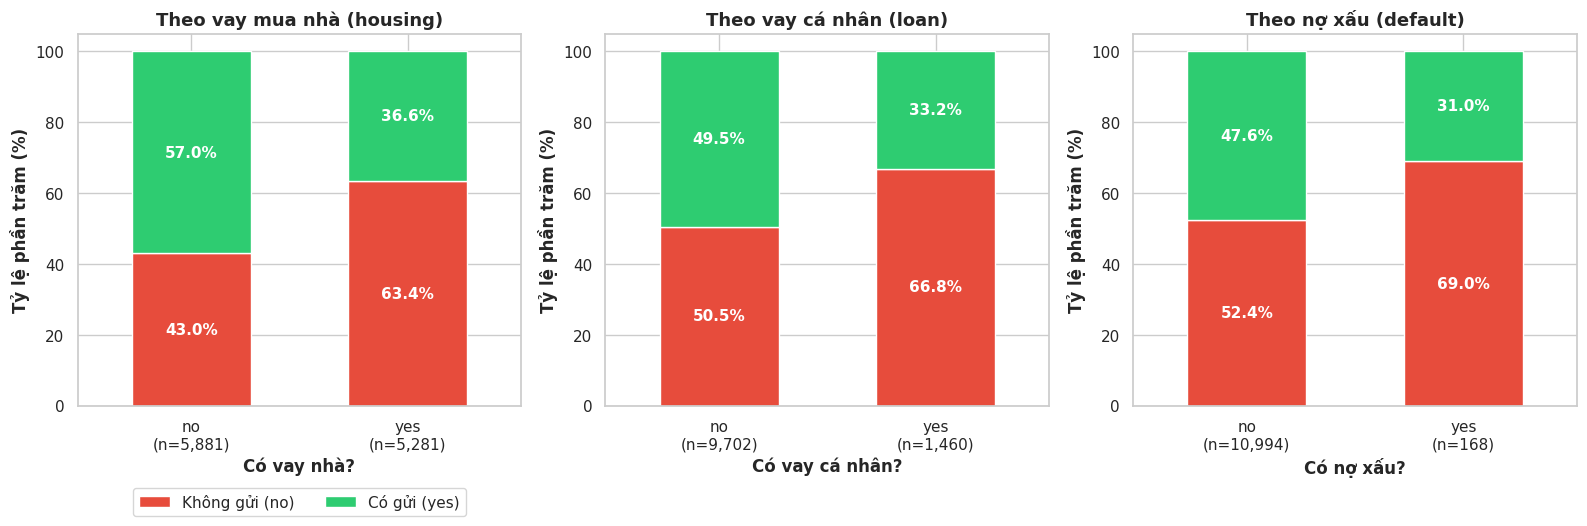

=== BẢNG SỐ LIỆU BIỂU ĐỒ 7A: VAY NHÀ ===
         Không gửi - No (SL)  Có gửi - Yes (SL)  Tổng KH  Tỷ lệ Yes (%)  Chênh so với mức chung (điểm %)
housing                                                                                                 
no                      2527               3354     5881          57.03                             9.65
yes                     3346               1935     5281          36.64                           -10.74 

=== BẢNG SỐ LIỆU BIỂU ĐỒ 7B: VAY CÁ NHÂN ===
      Không gửi - No (SL)  Có gửi - Yes (SL)  Tổng KH  Tỷ lệ Yes (%)  Chênh so với mức chung (điểm %)
loan                                                                                                 
no                   4897               4805     9702          49.53                             2.15
yes                   976                484     1460          33.15                           -14.23 

=== BẢNG SỐ LIỆU BIỂU ĐỒ 7C: NỢ XẤU ===
         Không gửi - No (SL)  Có gửi - Yes

In [22]:
# BIỂU ĐỒ 7: TỶ LỆ GỬI TIẾT KIỆM THEO VAY NHÀ (HOUSING), VAY CÁ NHÂN (LOAN), NỢ XẤU (DEFAULT)  -> H5
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
stacked_pct('housing', ['no', 'yes'], axes[0], 'Theo vay mua nhà (housing)', 'Có vay nhà?')
stacked_pct('loan', ['no', 'yes'], axes[1], 'Theo vay cá nhân (loan)', 'Có vay cá nhân?')
stacked_pct('default', ['no', 'yes'], axes[2], 'Theo nợ xấu (default)', 'Có nợ xấu?')
axes[0].legend(['Không gửi (no)', 'Có gửi (yes)'], loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.savefig('figures/bd7_housing_loan_default.png', dpi=150, bbox_inches='tight'); plt.show()

for col, name in [('housing', '7A: VAY NHÀ'), ('loan', '7B: VAY CÁ NHÂN'), ('default', '7C: NỢ XẤU')]:
    print(f"=== BẢNG SỐ LIỆU BIỂU ĐỒ {name} ===")
    print(summary_table(col, ['no', 'yes']).to_string(), "\n")

### Deep Insight – Biểu đồ 7 (H5: vay nhà, vay cá nhân, nợ xấu)
**Giả thuyết:** khách có vay hoặc nợ xấu có tỷ lệ gửi tiền thấp hơn.

- **Số liệu cụ thể:** vay nhà: no 57,03% (n = 5.881) và yes 36,64% (n = 5.281); vay cá nhân: no 49,53% (n = 9.702) và yes 33,15% (n = 1.460); nợ xấu: no 47,64% (n = 10.994) và yes 30,95% (n = 168).
- **So sánh:** chênh lệch giữa nhóm không vay và có vay là 20,39 điểm % với vay nhà, 16,38 điểm % với vay cá nhân và 16,69 điểm % với nợ xấu. Nhóm `default = yes` chỉ có 168 khách (khoảng 1,5% dữ liệu) nên kết luận kém tin cậy hơn hai biến còn lại.
- **Kết luận giả thuyết:** **H5 được ủng hộ** ở cả ba biến, mạnh nhất là vay nhà.
- **Bài học / hành động:** ưu tiên khách không có vay nhà và không vay cá nhân; khách đang gánh nợ ít có dư địa tiết kiệm nên cần sản phẩm hoặc cách tư vấn phù hợp hơn.

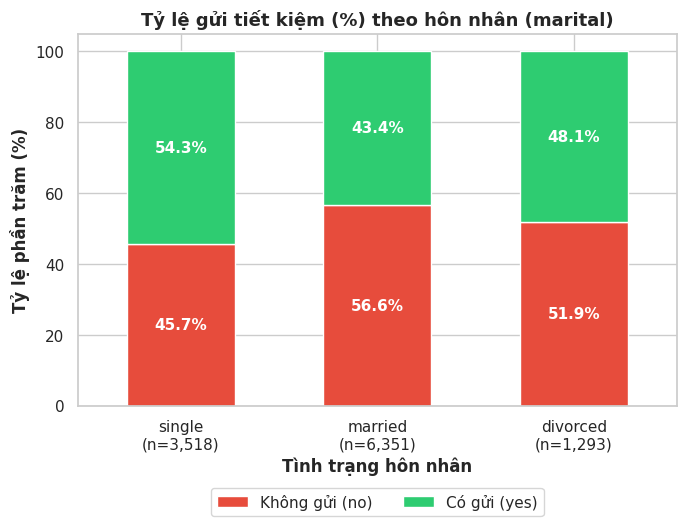

=== BẢNG SỐ LIỆU BIỂU ĐỒ 8: DEPOSIT THEO HÔN NHÂN (MARITAL) ===
          Không gửi - No (SL)  Có gửi - Yes (SL)  Tổng KH  Tỷ lệ Yes (%)  Chênh so với mức chung (điểm %)
marital                                                                                                  
single                   1606               1912     3518          54.35                             6.97
married                  3596               2755     6351          43.38                            -4.00
divorced                  671                622     1293          48.11                             0.73


In [23]:
# BIỂU ĐỒ 8: TỶ LỆ GỬI TIẾT KIỆM THEO TÌNH TRẠNG HÔN NHÂN (MARITAL)  -> H3
fig, ax = plt.subplots(figsize=(7, 5.5))
stacked_pct('marital', ['single', 'married', 'divorced'], ax, 'Tỷ lệ gửi tiết kiệm (%) theo hôn nhân (marital)', 'Tình trạng hôn nhân')
ax.legend(['Không gửi (no)', 'Có gửi (yes)'], loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.savefig('figures/bd8_marital.png', dpi=150, bbox_inches='tight'); plt.show()

print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 8: DEPOSIT THEO HÔN NHÂN (MARITAL) ===")
print(summary_table('marital', ['single', 'married', 'divorced']).to_string())

### Deep Insight – Biểu đồ 8 (H3b: hôn nhân)
**Giả thuyết:** khách độc thân gửi nhiều hơn khách đã kết hôn.

- **Số liệu cụ thể:** single 54,35% (n = 3.518); married 43,38% (n = 6.351); divorced 48,11% (n = 1.293).
- **So sánh:** khách độc thân cao hơn khách đã kết hôn 10,97 điểm %, cao hơn mức chung 6,97 điểm %; nhóm married thấp hơn mức chung 4,00 điểm %. Cả ba nhóm đều có n từ 1.293 trở lên nên đủ tin cậy.
- **Kết luận giả thuyết:** **H3b được ủng hộ:** độc thân gửi nhiều hơn rõ rệt; chênh lệch gần 11 điểm % là đáng kể (xem thêm kiểm định Chi-square ở mục 3.4).
- **Bài học / hành động:** ưu tiên khách độc thân; với khách đã kết hôn (nhóm đông nhất, 6.351 khách) nên thử cách tiếp cận theo nhu cầu gia đình.

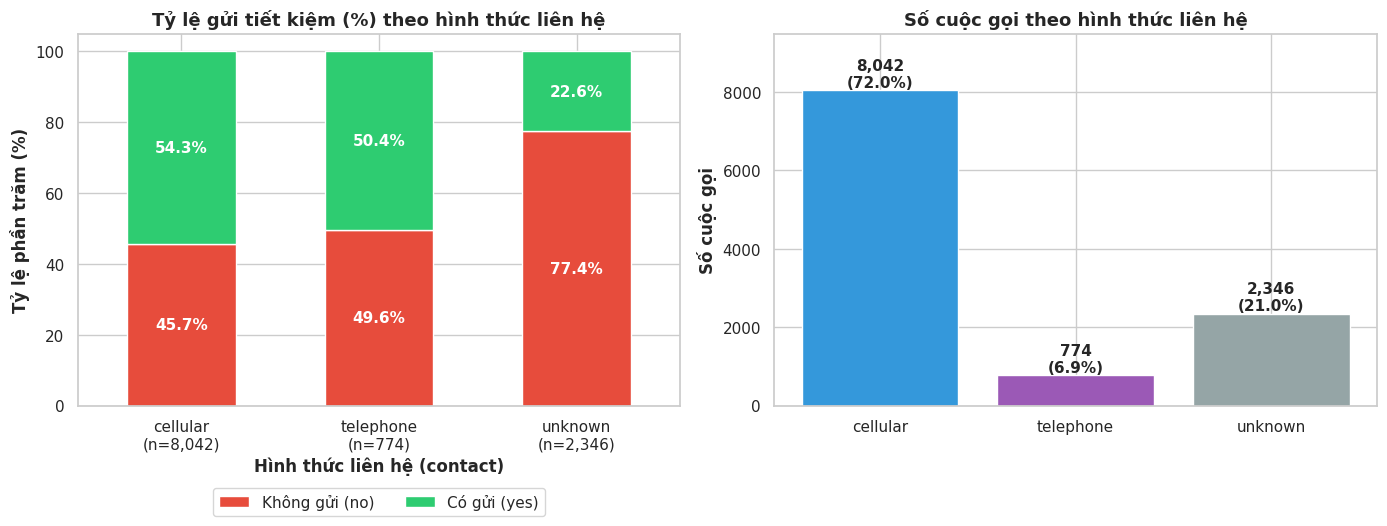

=== BẢNG SỐ LIỆU BIỂU ĐỒ 9: DEPOSIT THEO HÌNH THỨC LIÊN HỆ (CONTACT) ===
           Không gửi - No (SL)  Có gửi - Yes (SL)  Tổng KH  Tỷ lệ Yes (%)  Chênh so với mức chung (điểm %)
contact                                                                                                   
cellular                  3673               4369     8042          54.33                             6.95
telephone                  384                390      774          50.39                             3.01
unknown                   1816                530     2346          22.59                           -24.79


In [24]:
# BIỂU ĐỒ 9: TỶ LỆ GỬI TIẾT KIỆM THEO HÌNH THỨC LIÊN HỆ (CONTACT)  -> H7
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
order_ct = ['cellular', 'telephone', 'unknown']
stacked_pct('contact', order_ct, axes[0], 'Tỷ lệ gửi tiết kiệm (%) theo hình thức liên hệ', 'Hình thức liên hệ (contact)')
axes[0].legend(['Không gửi (no)', 'Có gửi (yes)'], loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

share = df_clean['contact'].value_counts().reindex(order_ct)
axes[1].bar(order_ct, share.values, color=['#3498db', '#9b59b6', '#95a5a6'])
for i, v in enumerate(share.values):
    axes[1].text(i, v + 80, f"{v:,}\n({v / len(df_clean) * 100:.1f}%)", ha='center', fontweight='bold')
axes[1].set_title('Số cuộc gọi theo hình thức liên hệ'); axes[1].set_ylabel('Số cuộc gọi', fontweight='bold')
axes[1].set_ylim(0, share.max() * 1.18)
plt.tight_layout(); plt.savefig('figures/bd9_contact.png', dpi=150, bbox_inches='tight'); plt.show()

print("=== BẢNG SỐ LIỆU BIỂU ĐỒ 9: DEPOSIT THEO HÌNH THỨC LIÊN HỆ (CONTACT) ===")
print(summary_table('contact', order_ct).to_string())

### Deep Insight – Biểu đồ 9 (H7: hình thức liên hệ)
**Giả thuyết:** gọi qua cellular hiệu quả hơn telephone và unknown.

- **Số liệu cụ thể:** cellular 54,33% (n = 8.042); telephone 50,39% (n = 774); unknown 22,59% (n = 2.346).
- **So sánh:** cellular cao hơn telephone chỉ 3,94 điểm % (nhóm telephone chỉ có 774 khách), nhưng cao hơn unknown tới 31,74 điểm %. Nhóm `unknown` chiếm 21,02% dữ liệu và thấp hơn mức chung 24,79 điểm %.
- **Kết luận giả thuyết:** **H7 được ủng hộ một phần:** cellular cao nhất, nhưng chênh lệch với telephone nhỏ; điểm khác biệt lớn nhất là nhóm `unknown` thấp rõ rệt, có thể liên quan đến việc không xác định được kênh liên hệ (đây là giả thuyết, chưa kiểm chứng được bằng dữ liệu).
- **Bài học / hành động:** ưu tiên liên lạc qua điện thoại di động và ghi nhận đầy đủ kênh liên hệ của từng cuộc gọi để phân tích chính xác hơn.

## 3.4. Kiểm định thống kê
- **Chi-square:** kiểm tra biến phân loại có liên hệ thật với `deposit` không (H0: hai biến độc lập). **Cramér's V** đo *độ mạnh* của liên hệ (0 đến 1).
- **t-test (Welch) và Mann-Whitney:** kiểm tra biến số giữa nhóm yes và no có khác biệt thật không. Mann-Whitney làm đối chứng vì các biến lệch phải.
- **Cách đọc p-value:** p-value < 0,05 nghĩa là khác biệt khó có thể chỉ do ngẫu nhiên. Dữ liệu hơn 11 nghìn dòng nên p-value thường rất nhỏ; cần xem thêm **mức chênh thực tế** và Cramér's V.

In [25]:
# 3.4a. KIỂM ĐỊNH CHI-SQUARE VÀ CRAMÉR'S V (BIẾN PHÂN LOẠI ↔ DEPOSIT)
from scipy.stats import chi2_contingency, ttest_ind, mannwhitneyu

df_test = df_clean.copy()
df_test['age_group'] = pd.cut(df_test['age'], bins=[0, 25, 35, 50, 60, 100], labels=['≤25', '26-35', '36-50', '51-60', '>60'])

def cramers_v(table):
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

def muc_do(v):
    return 'rất yếu' if v < 0.1 else ('yếu' if v < 0.3 else ('vừa' if v < 0.5 else 'mạnh'))

rows = []
for col in ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'age_group']:
    table = pd.crosstab(df_test[col], df_test['deposit'])
    chi2, p, dof, _ = chi2_contingency(table)
    v = cramers_v(table)
    rows.append({'Biến': col, 'Chi2': f"{chi2:.1f}", 'Bậc tự do': dof, 'p-value': f"{p:.2e}",
                 "Cramér's V": f"{v:.3f}", 'Mức độ liên hệ (tham khảo)': muc_do(v),
                 'Kết luận (α = 0.05)': 'Có liên hệ với deposit' if p < 0.05 else 'Chưa thấy liên hệ'})
chi_result = pd.DataFrame(rows)
print("=== KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE ===")
print(chi_result.to_string(index=False))

=== KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE ===
     Biến   Chi2  Bậc tự do   p-value Cramér's V Mức độ liên hệ (tham khảo)    Kết luận (α = 0.05)
      job  378.0         10  4.61e-75      0.184                        yếu Có liên hệ với deposit
  marital  109.6          2  1.60e-24      0.099                    rất yếu Có liên hệ với deposit
education  116.3          2  5.65e-26      0.102                        yếu Có liên hệ với deposit
  default   17.8          1  2.44e-05      0.041                    rất yếu Có liên hệ với deposit
  housing  463.2          1 9.72e-103      0.204                        yếu Có liên hệ với deposit
     loan  135.8          1  2.17e-31      0.111                        yếu Có liên hệ với deposit
  contact  736.7          2 1.07e-160      0.257                        yếu Có liên hệ với deposit
    month 1046.8         11 1.64e-217      0.306                        vừa Có liên hệ với deposit
 poutcome 1004.6          3 1.78e-217      0.300                        

In [26]:
# 3.4b. KIỂM ĐỊNH t-test (WELCH) VÀ MANN-WHITNEY (BIẾN SỐ: NHÓM YES SO VỚI NHÓM NO, DÙNG DỮ LIỆU GỐC df_clean)
rows = []
for col in ['age', 'balance', 'duration', 'campaign', 'previous', 'day']:
    yes_vals = df_clean.loc[df_clean['deposit'] == 'yes', col]
    no_vals = df_clean.loc[df_clean['deposit'] == 'no', col]
    p_t = ttest_ind(yes_vals, no_vals, equal_var=False)[1]
    p_u = mannwhitneyu(yes_vals, no_vals, alternative='two-sided')[1]
    if max(p_t, p_u) < 0.05:
        kl = 'Khác biệt có ý nghĩa'
    elif min(p_t, p_u) >= 0.05:
        kl = 'Chưa thấy khác biệt'
    else:
        kl = 'Hai phép không thống nhất, cần thận trọng'
    rows.append({'Biến': col, 'Trung vị yes': f"{yes_vals.median():.0f}", 'Trung vị no': f"{no_vals.median():.0f}",
                 'TB yes': f"{yes_vals.mean():.1f}", 'TB no': f"{no_vals.mean():.1f}",
                 'p t-test': f"{p_t:.2e}", 'p Mann-Whitney': f"{p_u:.2e}", 'Kết luận (α = 0.05)': kl})
num_result = pd.DataFrame(rows)
print("=== KẾT QUẢ t-test (WELCH) VÀ MANN-WHITNEY ===")
print(num_result.to_string(index=False))

=== KẾT QUẢ t-test (WELCH) VÀ MANN-WHITNEY ===
    Biến Trung vị yes Trung vị no TB yes  TB no p t-test p Mann-Whitney                       Kết luận (α = 0.05)
     age           38          39   41.7   40.8 2.76e-04       1.99e-01 Hai phép không thống nhất, cần thận trọng
 balance          733         414 1804.3 1280.2 1.81e-17       3.13e-62                      Khác biệt có ý nghĩa
duration          426         163  537.3  223.1 0.00e+00       0.00e+00                      Khác biệt có ý nghĩa
campaign            2           2    2.1    2.8 4.77e-44       7.73e-41                      Khác biệt có ý nghĩa
previous            0           0    1.2    0.5 1.36e-48      2.60e-130                      Khác biệt có ý nghĩa
     day           15          16   15.2   16.1 2.71e-09       7.19e-10                      Khác biệt có ý nghĩa


### Deep Insight – Kiểm định Chi-square, t-test, Mann-Whitney (mục 3.4)
**Giả thuyết:** các biến có liên hệ thật với `deposit` hay chỉ do ngẫu nhiên.

- **Số liệu cụ thể:** Chi-square cho thấy cả 10 biến phân loại đều có liên hệ có ý nghĩa với `deposit` (p < 0,05); mạnh nhất theo Cramér's V là `month` (V = 0,306), `poutcome` (V = 0,300) và `contact` (V = 0,257). Với biến số, t-test và Mann-Whitney đều cho khác biệt có ý nghĩa ở balance, duration, campaign, previous, day; riêng `age` hai phép không thống nhất (tuổi trung bình yes 41,67 so với no 40,84).
- **So sánh:** dữ liệu hơn 11 nghìn dòng nên p-value thường rất nhỏ (giá trị hiển thị `0.00e+00` nghĩa là p < 0,001); vì vậy cần xem thêm mức chênh thực tế và Cramér's V. Các giá trị V quanh 0,26 đến 0,31 cho thấy liên hệ ở mức vừa phải chứ không quá mạnh.
- **Kết luận giả thuyết:** các kết quả kiểm định **xác nhận** hướng của H1 đến H10 ở mức có ý nghĩa thống kê; riêng tuổi cần thận trọng vì tuổi trung bình hai nhóm gần như bằng nhau, sự khác biệt chủ yếu nằm ở dạng chữ U theo nhóm tuổi.
- **Bài học / hành động:** khi lập kế hoạch tiếp thị nên ưu tiên các yếu tố có liên hệ mạnh nhất là tháng, kết quả chiến dịch trước và hình thức liên hệ, và đọc kèm bảng tỷ lệ theo nhóm thay vì chỉ dựa vào p-value.

## 3.5. Bảng tổng hợp giả thuyết H1 – H10

In [27]:
# 3.5. BẢNG TỔNG HỢP GIẢ THUYẾT H1-H10 (SỐ LIỆU CHÍNH TỰ TÍNH TỪ DỮ LIỆU)
d = df_clean.copy()
d['age_group'] = pd.cut(d['age'], bins=[0, 25, 35, 50, 60, 100], labels=['≤25', '26-35', '36-50', '51-60', '>60'])
q_edges = d['balance'].quantile([0, 0.25, 0.5, 0.75, 1]).values
d['balance_group'] = pd.cut(d['balance'], bins=q_edges, include_lowest=True, labels=['Q1', 'Q2', 'Q3', 'Q4'])
d['duration_group'] = pd.cut(d['duration'], bins=[0, 180, 300, 600, 5000], labels=['≤3p', '3-5p', '5-10p', '>10p'])
d['campaign_group'] = pd.cut(d['campaign'], bins=[0, 1, 2, 3, 4, 5, 10, 100], labels=['1', '2', '3', '4', '5', '6-10', '>10'])

def key_line(col, order=None):
    t = summary_table(col, order, data=d)
    hi, lo = t['Tỷ lệ Yes (%)'].idxmax(), t['Tỷ lệ Yes (%)'].idxmin()
    return (f"{hi} {t.loc[hi, 'Tỷ lệ Yes (%)']:.1f}% (n={t.loc[hi, 'Tổng KH']:,}) so với "
            f"{lo} {t.loc[lo, 'Tỷ lệ Yes (%)']:.1f}% (n={t.loc[lo, 'Tổng KH']:,}); chung {overall_rate:.1f}%")

summary_h = pd.DataFrame([
    ['H1', 'Khách lớn tuổi gửi nhiều hơn khách trẻ', key_line('age_group'), 'Ủng hộ một phần (dạng chữ U: nhóm ≤25 và >60 cao)'],
    ['H2', 'Student, retired cao hơn blue-collar, services', key_line('job'), 'Ủng hộ'],
    ['H3', 'Học vấn cao và độc thân gửi nhiều hơn', 'Học vấn: ' + key_line('education') + ' | Hôn nhân: ' + key_line('marital'), 'Ủng hộ'],
    ['H4', 'Số dư cao thì tỷ lệ cao hơn', key_line('balance_group'), 'Ủng hộ'],
    ['H5', 'Có vay hoặc nợ xấu thì tỷ lệ thấp hơn', 'Vay nhà: ' + key_line('housing') + ' | Vay cá nhân: ' + key_line('loan') + ' | Nợ xấu: ' + key_line('default'), 'Ủng hộ (nhóm nợ xấu chỉ có 168 khách)'],
    ['H6', 'Tỷ lệ khác nhau rõ giữa các tháng', key_line('month'), 'Ủng hộ (tháng ít cuộc gọi kém tin cậy)'],
    ['H7', 'Cellular hiệu quả hơn telephone và unknown', key_line('contact'), 'Ủng hộ một phần (cellular cao nhất nhưng chênh telephone nhỏ)'],
    ['H8', 'Gọi lâu hơn thì tỷ lệ cao hơn (là kết quả)', key_line('duration_group'), 'Ủng hộ (là kết quả sau cuộc gọi)'],
    ['H9', 'Gọi nhiều lần thì tỷ lệ giảm', key_line('campaign_group'), 'Ủng hộ'],
    ['H10', 'poutcome = success cao hơn rất nhiều', key_line('poutcome'), 'Ủng hộ rất mạnh'],
], columns=['Giả thuyết', 'Nội dung', 'Số liệu chính', 'Kết luận'])
pd.set_option('display.max_colwidth', 400)
display(summary_h)
summary_h.to_csv('figures/bang_tong_hop_H1_H10.csv', index=False, encoding='utf-8-sig')

,Giả thuyết,Nội dung,Số liệu chính,Kết luận
0,H1,Khách lớn tuổi gửi nhiều hơn khách trẻ,">60 82.2% (n=611) so với 36-50 41.4% (n=4,320); chung 47.4%",Ủng hộ một phần (dạng chữ U: nhóm ≤25 và >60 cao)
1,H2,"Student, retired cao hơn blue-collar, services","student 74.7% (n=360) so với blue-collar 36.4% (n=1,944); chung 47.4%",Ủng hộ
2,H3,Học vấn cao và độc thân gửi nhiều hơn,"Học vấn: tertiary 54.1% (n=3,689) so với primary 39.4% (n=1,500); chung 47.4% | Hôn nhân: single 54.4% (n=3,518) so với married 43.4% (n=6,351); chung 47.4%",Ủng hộ
3,H4,Số dư cao thì tỷ lệ cao hơn,"Q4 57.5% (n=2,790) so với Q1 36.0% (n=2,792); chung 47.4%",Ủng hộ
4,H5,Có vay hoặc nợ xấu thì tỷ lệ thấp hơn,"Vay nhà: no 57.0% (n=5,881) so với yes 36.6% (n=5,281); chung 47.4% | Vay cá nhân: no 49.5% (n=9,702) so với yes 33.1% (n=1,460); chung 47.4% | Nợ xấu: no 47.6% (n=10,994) so với yes 30.9% (n=168); chung 47.4%",Ủng hộ (nhóm nợ xấu chỉ có 168 khách)
5,H6,Tỷ lệ khác nhau rõ giữa các tháng,"dec 90.9% (n=110) so với may 32.8% (n=2,824); chung 47.4%",Ủng hộ (tháng ít cuộc gọi kém tin cậy)
6,H7,Cellular hiệu quả hơn telephone và unknown,"cellular 54.3% (n=8,042) so với unknown 22.6% (n=2,346); chung 47.4%",Ủng hộ một phần (cellular cao nhất nhưng chênh telephone nhỏ)
7,H8,Gọi lâu hơn thì tỷ lệ cao hơn (là kết quả),">10p 85.2% (n=2,152) so với ≤3p 18.0% (n=3,936); chung 47.4%",Ủng hộ (là kết quả sau cuộc gọi)
8,H9,Gọi nhiều lần thì tỷ lệ giảm,"1 53.4% (n=4,798) so với >10 22.4% (n=210); chung 47.4%",Ủng hộ
9,H10,poutcome = success cao hơn rất nhiều,"success 91.3% (n=1,071) so với unknown 40.7% (n=8,326); chung 47.4%",Ủng hộ rất mạnh


---
# PHẦN 4: ĐÁNH GIÁ TÁC ĐỘNG VÀ KHUYẾN NGHỊ

## 4.1. Các phát hiện nổi bật nhất
1. **Kết quả chiến dịch trước phân biệt khách rất rõ:** khách `poutcome = success` gửi tiền 91,32% (n = 1.071), cao hơn mức chung 47,38% khoảng 43,9 điểm %; nhóm `unknown` chỉ 40,67% (n = 8.326).
2. **Hiệu quả không đi cùng khối lượng cuộc gọi theo tháng:** tháng 5 chiếm 25,30% số cuộc gọi (2.824) nhưng chỉ 32,75% đăng ký, thấp hơn mức chung; các tháng 3, 9, 10, 12 đạt 82-91% nhưng ít cuộc gọi (110-392) nên cần thận trọng khi khái quát.
3. **Gọi nhiều lần làm giảm hiệu quả:** tỷ lệ giảm từ 53,38% (1 lần) xuống 22,38% (> 10 lần); từ nhóm **4 lần gọi** tỷ lệ thấp hơn mức chung ít nhất 5 điểm %.
4. **Nhóm khách có xác suất cao:** khách > 60 tuổi 82,16% (n = 611), student 74,72% (n = 360), retired 66,32%; nhóm có vay nhà thấp hơn rõ (36,6% so với 57,0% ở nhóm không vay).
5. **Thời lượng cuộc gọi liên quan rất mạnh đến kết quả** (> 10 phút đạt 85,18%, ≤ 3 phút chỉ 18,01%) nhưng đây là **kết quả sau cuộc gọi**, không dùng để hành động trước cuộc gọi.

## 4.2. Giải pháp thực tế (Hành động → Căn cứ số liệu → Lợi ích kỳ vọng)
| Hành động | Căn cứ số liệu | Lợi ích kỳ vọng |
|---|---|---|
| Ưu tiên gọi lại khách đã từng `success` ở chiến dịch trước | H10: 91,3% so với mức chung 47,4% | Tăng tỷ lệ chuyển đổi, giảm chi phí mỗi khách thành công |
| Đặt ngưỡng dừng tối đa 3 lần gọi mỗi khách (từ lần thứ 4 tỷ lệ thấp hơn mức chung ít nhất 5 điểm %, theo biểu đồ 4D) | H9: tỷ lệ giảm từ 53,4% (1 lần) xuống 22,4% (> 10 lần) | Tiết kiệm chi phí, tránh làm phiền khách |
| Cân đối lại nguồn lực theo tháng, không dồn quá nhiều cuộc gọi vào tháng 5 | H6: tháng 5 chiếm 25,3% cuộc gọi nhưng chỉ 32,8% đăng ký | Tăng hiệu quả trên mỗi cuộc gọi |
| Ưu tiên khách không vay nhà và nhóm khách lớn tuổi, student, retired | H5, H1, H2 | Tập trung vào nhóm có xác suất cao |
| Ưu tiên liên lạc qua điện thoại di động và làm rõ kênh liên hệ chưa xác định | H7: cellular 54,3% so với unknown 22,6% | Tiếp cận hiệu quả hơn |

## 4.3. Giới hạn của tập dữ liệu
- Dữ liệu của **một ngân hàng**, không có thông tin thu nhập, chi phí cuộc gọi, ngày/năm cụ thể (không đánh giá được xu hướng theo thời gian dài).
- `duration` **chỉ biết sau cuộc gọi**, nên không thể dùng để dự đoán trước khi gọi.
- `unknown` rất cao ở `poutcome` (74,59%) và `contact` (21,02%); điền Mode ở `job`/`education` có thể làm lệch nhẹ.
- Tháng 5 chiếm 25,3% cuộc gọi, các tháng khác rất ít dữ liệu (mar, sep, oct, dec) nên tỷ lệ theo tháng kém ổn định.
- Phân tích chỉ chứng minh **mối liên hệ**, chưa chứng minh **nhân quả**.

## 4.4. Hướng mở rộng
- Xây **mô hình dự đoán** (Logistic Regression, Random Forest) **không dùng `duration`**, dùng `df_processed` đã chuẩn bị ở Giai đoạn 2.
- Thu thêm dữ liệu: thu nhập, nhiều ngân hàng, nhiều năm; thử **A/B testing** cho ngưỡng số lần gọi và hình thức liên hệ.

---
# Lưu hình biểu đồ
Ô dưới lưu các bảng số liệu vào thư mục `tables/`, liệt kê các hình trong `figures/` và nén thành `figures.zip`, `tables.zip` để tải về máy khi chạy trên Colab.

In [28]:
# LƯU BẢNG + HÌNH: XUẤT CÁC BẢNG SỐ LIỆU RA THƯ MỤC tables, NÉN figures + tables THÀNH figures.zip
import os, shutil
attr_table.to_csv('tables/bang_thuoc_tinh.csv', index=False, encoding='utf-8-sig')
df_missing_report.to_csv('tables/bang_khuyet_thieu_unknown.csv', index=False, encoding='utf-8-sig')
detect_outliers_iqr(df_clean, num_cols_outlier).to_csv('tables/bang_outlier_truoc_capping.csv', index=False, encoding='utf-8-sig')
chi_result.to_csv('tables/kiem_dinh_chi_square.csv', index=False, encoding='utf-8-sig')
num_result.to_csv('tables/kiem_dinh_ttest_mannwhitney.csv', index=False, encoding='utf-8-sig')
summary_h.to_csv('tables/bang_tong_hop_H1_H10.csv', index=False, encoding='utf-8-sig')

png_files = sorted(f for f in os.listdir('figures') if f.endswith('.png'))
csv_files = sorted(os.listdir('tables'))
print(f"Đã lưu {len(png_files)} hình trong figures/:")
for f in png_files: print("  -", f)
print(f"Đã lưu {len(csv_files)} bảng trong tables/:")
for f in csv_files: print("  -", f)

shutil.make_archive('figures', 'zip', '.', 'figures')
shutil.make_archive('tables', 'zip', '.', 'tables')
try:
    from google.colab import files
    files.download('figures.zip'); files.download('tables.zip')   # tải về máy khi chạy trên Colab
except ImportError:
    print("Không chạy trên Colab: figures.zip và tables.zip nằm trong thư mục hiện tại.")


Đã lưu 12 hình trong figures/:
  - bd1_deposit.png
  - bd2_job_education.png
  - bd3_age_balance.png
  - bd3c_balance_nhom.png
  - bd4_duration_campaign.png
  - bd4d_campaign_nguong_dung.png
  - bd5_month_poutcome.png
  - bd6_heatmap.png
  - bd7_housing_loan_default.png
  - bd8_marital.png
  - bd9_contact.png
  - bd_outlier_truoc_sau_capping.png
Đã lưu 6 bảng trong tables/:
  - bang_khuyet_thieu_unknown.csv
  - bang_outlier_truoc_capping.csv
  - bang_thuoc_tinh.csv
  - bang_tong_hop_H1_H10.csv
  - kiem_dinh_chi_square.csv
  - kiem_dinh_ttest_mannwhitney.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>